# Projeto 06 — Airbnb NYC · Notebook 02: representação, normalização, K-Means e DBSCAN

Este notebook parte das decisões aprovadas no Checkpoint 1 (notebook 01) e segue o roteiro do enunciado:

| Seção | Conteúdo |
|---|---|
| 1–2 | Clusterizar ≠ classificar; distância e representações de features |
| 3 | Experimento controlado **A** (sem scaling) × **B** (com `StandardScaler`) |
| 4–5 | K-Means: conceitos e escolha de K (K = 2…10, Elbow e quatro métricas); K = 7 aprovado no Checkpoint 2 |
| 6 | Representações alternativas R1 e R3 |
| 7 | DBSCAN: conceitos, amostra, k-distâncias, grade, ruído, DBSCAN só numérico e comparação justa com o K-Means |
| 8 | Segmentos finais: perfis, composição, distribuições, PCA 2D, mapa e segmentos mais distintos |
| 9 | Decisão final |
| 10 | Respostas às 14 perguntas finais do enunciado |

Todos os números vêm das células executadas. Notebook e scripts usam as mesmas funções de `src/`.

**Como executar** (na raiz do projeto, com o `.venv` ativado):

```bash
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/02_clustering.ipynb
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score

from src import config, data, evaluation, plots, preprocessing, profiling

plots.apply_style()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 170
config.REPORTS_DIR.mkdir(exist_ok=True)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

raw = data.load_raw()
listings, cleaning_log = data.clean_listings(raw)
print(f"base clusterizada: {len(listings):,} anúncios (removidos: {int(cleaning_log['n_removed'].sum())} com price = 0)".replace(",", "."))

pandas 3.0.5 | numpy 2.4.6 | scikit-learn 1.9.0


base clusterizada: 48.884 anúncios (removidos: 11 com price = 0)


## 1. Clusterizar não é classificar

Nos projetos anteriores havia um alvo conhecido (preço, chuva, inadimplência), e o modelo aprendia a reproduzi-lo. Aqui **não existe
rótulo de segmento**. O K-Means e o DBSCAN só organizam os anúncios a partir da semelhança entre eles, e a semelhança depende
inteiramente de como representamos cada anúncio (features, transformações, escala).

Por isso não há accuracy, ROC-AUC ou KS: todas comparam uma previsão com uma resposta verdadeira, e aqui não existe resposta
verdadeira. As métricas internas (inertia, Silhouette, Davies-Bouldin, Calinski-Harabasz) medem só a **geometria** da partição:
compactação e separação no espaço escolhido. Elas não dizem se os grupos servem para o negócio. Essa parte depende da leitura dos
perfis.

## 2. Distância Euclidiana e representações

Cada anúncio vira um **ponto**: um vetor com uma coordenada por **feature** transformada. A **distância Euclidiana** entre dois
anúncios é a raiz da soma das diferenças quadráticas em cada coordenada. "Parecido", portanto, significa "perto neste espaço", e
quem decide o que pesa na distância é a escala de cada coordenada.

Representações comparadas, todas sobre as **mesmas 48.884 linhas**:

| Representação | Numéricas (tratamento aprovado no Checkpoint 1) | Categóricas (OneHot) | Papel |
|---|---|---|---|
| R1 | `price`, `minimum_nights`, `availability_365`, `reviews_per_month`, `calculated_host_listings_count` | — | comparação: só perfil numérico |
| **R2** | as mesmas 5 | `room_type` | **proposta principal** |
| R3 | as mesmas 5 | `room_type`, `neighbourhood_group` | teste: a geografia transforma os grupos em recortes por distrito? |

Tratamento das numéricas, em `src/preprocessing.py`:
1. `reviews_per_month` ausente vira 0;
2. winsorização em p99,5 para `price` e `reviews_per_month` (limite aprendido no `fit`) e teto de 365 em `minimum_nights`;
3. `log1p` em `price`, `minimum_nights`, `reviews_per_month` e `calculated_host_listings_count`;
4. `StandardScaler` (cenário B) ou nada (cenário A).

As dummies não são escalonadas.

In [2]:
prep_a = preprocessing.make_preprocessor("R2", scale=False).fit(listings)
prep_b = preprocessing.make_preprocessor("R2", scale=True).fit(listings)
X_a = prep_a.transform(listings)
X_b = prep_b.transform(listings)
feature_names = list(prep_b.get_feature_names_out())
caps = prep_b.named_transformers_["num"].named_steps["treat"].caps_
print("colunas do espaço R2:", feature_names)
print("limites aprendidos no fit:", {k: round(v, 2) for k, v in caps.items()})
pd.DataFrame(X_b, columns=feature_names).describe().T[["mean", "std", "min", "max"]]

colunas do espaço R2: ['num__price', 'num__minimum_nights', 'num__availability_365', 'num__reviews_per_month', 'num__calculated_host_listings_count', 'cat__room_type_Entire home/apt', 'cat__room_type_Private room', 'cat__room_type_Shared room']
limites aprendidos no fit: {'minimum_nights': 365.0, 'price': 1000.0, 'reviews_per_month': 7.97}


,mean,std,min,max
num__price,0.000,1.000,-3.448,3.209
num__minimum_nights,0.000,1.000,-0.928,5.067
num__availability_365,0.000,1.000,-0.857,1.916
num__reviews_per_month,-0.000,1.000,-0.943,2.876
num__calculated_host_listings_count,-0.000,1.000,-0.459,5.480
cat__room_type_Entire home/apt,0.520,0.500,0.000,1.000
cat__room_type_Private room,0.457,0.498,0.000,1.000
cat__room_type_Shared room,0.024,0.152,0.000,1.000


## 3. Experimento controlado: sem (A) e com (B) normalização

As duas condições usam **as mesmas linhas, as mesmas features, o mesmo tratamento e o mesmo encoding**:

- **A:** tratamento + encoding, sem scaling das numéricas;
- **B:** o mesmo, com `StandardScaler` nas numéricas.

### 3.1 Quanto cada feature pesa na distância

Para dois anúncios sorteados ao acaso, a diferença quadrática esperada em uma coluna é **2 × variância** dessa coluna. Logo, a fatia
de cada coluna na distância quadrática média é a variância dela dividida pela soma das variâncias. A conta é exata e não exige
nenhuma matriz de distâncias.

In [3]:
contrib_a = evaluation.variance_contribution(X_a, feature_names)
contrib_b = evaluation.variance_contribution(X_b, feature_names)
contribution = pd.DataFrame({
    "variância A": contrib_a["variance"].to_numpy(),
    "% da distância² A": contrib_a["pct_of_squared_distance"].to_numpy(),
    "variância B": contrib_b["variance"].to_numpy(),
    "% da distância² B": contrib_b["pct_of_squared_distance"].to_numpy(),
}, index=feature_names)
contribution.to_csv(config.REPORTS_DIR / "scaling_variance_contribution.csv")
by_block = pd.DataFrame({
    "% da distância² A": contrib_a.groupby("block", sort=False)["pct_of_squared_distance"].sum(),
    "% da distância² B": contrib_b.groupby("block", sort=False)["pct_of_squared_distance"].sum(),
})
display(contribution)
by_block

,variância A,% da distância² A,variância B,% da distância² B
num__price,0.459,0.003,1.000,18.113
num__minimum_nights,0.755,0.004,1.000,18.113
num__availability_365,"17,325.384",99.984,1.000,18.113
num__reviews_per_month,0.330,0.002,1.000,18.113
num__calculated_host_listings_count,0.737,0.004,1.000,18.113
cat__room_type_Entire home/apt,0.250,0.001,0.250,4.521
cat__room_type_Private room,0.248,0.001,0.248,4.494
cat__room_type_Shared room,0.023,0.000,0.023,0.419


,% da distância² A,% da distância² B
block,,
price,0.003,18.113
minimum_nights,0.004,18.113
availability_365,99.984,18.113
reviews_per_month,0.002,18.113
calculated_host_listings_count,0.004,18.113
room_type,0.003,9.434


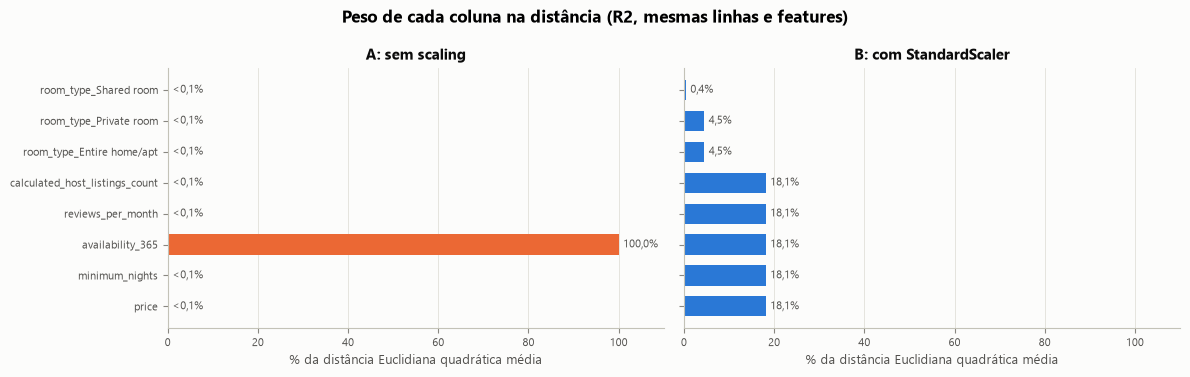

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
short_names = [name.split("__", 1)[1] for name in feature_names]
for ax, (label, table), color in zip(axes, [("A: sem scaling", contrib_a), ("B: com StandardScaler", contrib_b)],
                                     [plots.SERIES_COLORS[1], plots.SERIES_COLORS[0]]):
    values = table["pct_of_squared_distance"].to_numpy()
    y = np.arange(len(values))
    ax.barh(y, values, color=color, height=0.65)
    for yi, value in zip(y, values):
        text = "<0,1%" if value < 0.1 else f"{value:.1f}%".replace(".", ",")
        ax.text(value + 1, yi, text, va="center", fontsize=8, color=plots.INK_SECONDARY)
    ax.set_yticks(y, short_names)
    ax.invert_yaxis()
    ax.set_xlim(0, 110)
    ax.set_xlabel("% da distância Euclidiana quadrática média")
    ax.set_title(label)
    ax.grid(axis="y", visible=False)
fig.suptitle("Peso de cada coluna na distância (R2, mesmas linhas e features)", fontsize=12, fontweight="bold")
fig.tight_layout()
plots.save_figure(fig, "scaling_variance_contribution")
plt.show()

**Leitura.**

- **Cenário A:** `availability_365` responde por **99,98%** da distância quadrática média. A variância dela (17.325, em dias²) é
  milhares de vezes maior que a das numéricas em log (0,33 a 0,76) e a das dummies (no máximo 0,25). Em A, "parecido" significa,
  na prática, "com disponibilidade declarada parecida". As outras quatro numéricas e o `room_type` quase não contam.
- **Cenário B:** cada numérica passa a valer 18,1%, e o bloco `room_type` soma 9,4%.

A normalização não é um detalhe técnico: ela decide **quais características definem semelhança**.

### 3.2 Experimento-chave: anúncios hipotéticos

Três anúncios fictícios, definidos no código abaixo, passam pelos **mesmos** pré-processadores ajustados acima:

- **Anúncio 1:** imóvel inteiro, US$ 150, 2 noites mínimas, 300 dias disponíveis, 1 avaliação/mês, anfitrião com 1 anúncio.
- **Anúncio 2:** igual ao 1, mas é **quarto privado** a **US$ 60** e declara 290 dias disponíveis.
- **Anúncio 3:** igual ao 1 (mesmo tipo e mesmo preço), mas declara só **120 dias** disponíveis.

A pergunta é qual dos dois é "mais parecido" com o anúncio 1 em cada cenário, e qual feature domina cada distância.

In [5]:
hypothetical = pd.DataFrame([
    {"label": "anúncio 1", "room_type": "Entire home/apt", "price": 150, "minimum_nights": 2, "availability_365": 300,
     "reviews_per_month": 1.0, "calculated_host_listings_count": 1},
    {"label": "anúncio 2", "room_type": "Private room", "price": 60, "minimum_nights": 2, "availability_365": 290,
     "reviews_per_month": 1.0, "calculated_host_listings_count": 1},
    {"label": "anúncio 3", "room_type": "Entire home/apt", "price": 150, "minimum_nights": 2, "availability_365": 120,
     "reviews_per_month": 1.0, "calculated_host_listings_count": 1},
]).set_index("label")
display(hypothetical)

rows = []
decompositions = {}
for scenario, prep in [("A (sem scaling)", prep_a), ("B (com scaling)", prep_b)]:
    points = prep.transform(hypothetical)
    for other in (1, 2):
        table = evaluation.distance_decomposition(points[0], points[other], short_names)
        decompositions[(scenario, other + 1)] = table.set_index("feature")["pct_of_squared_distance"]
        dominant = table.loc[table["squared_difference"].idxmax()]
        rows.append({
            "cenário": scenario,
            "par": f"1 x {other + 1}",
            "distância": float(np.sqrt(table["squared_difference"].sum())),
            "feature dominante": dominant["feature"],
            "% da distância² na dominante": float(dominant["pct_of_squared_distance"]),
        })
pairs = pd.DataFrame(rows)
pairs.to_csv(config.REPORTS_DIR / "scaling_hypothetical_distances.csv", index=False)
display(pairs)
pd.DataFrame(decompositions).round(1)

,room_type,price,minimum_nights,availability_365,reviews_per_month,calculated_host_listings_count
label,,,,,,
anúncio 1,Entire home/apt,150,2,300,1.000,1
anúncio 2,Private room,60,2,290,1.000,1
anúncio 3,Entire home/apt,150,2,120,1.000,1


,cenário,par,distância,feature dominante,% da distância² na dominante
0,A (sem scaling),1 x 2,10.140,availability_365,97.256
1,A (sem scaling),1 x 3,180.000,availability_365,100.000
2,B (com scaling),1 x 2,1.948,price,47.147
3,B (com scaling),1 x 3,1.368,availability_365,100.000


A (sem scaling)         B (com scaling)        
                                             2       3               2       3
feature                                                                       
price                                    0.800   0.000          47.100   0.000
minimum_nights                           0.000   0.000           0.000   0.000
availability_365                        97.300 100.000           0.200 100.000
reviews_per_month                        0.000   0.000           0.000   0.000
calculated_host_listings_count           0.000   0.000           0.000   0.000
room_type_Entire home/apt                1.000   0.000          26.400   0.000
room_type_Private room                   1.000   0.000          26.400   0.000
room_type_Shared room                    0.000   0.000           0.000   0.000

**Leitura.**

- **Cenário A:** o anúncio 1 fica **mais perto do anúncio 2** (distância 10,1), um quarto privado por menos da metade do preço,
  do que do anúncio 3 (distância 180), que é o mesmo tipo de imóvel ao mesmo preço e só difere na disponibilidade. Dez dias de
  diferença em `availability_365` pesam mais do que trocar o tipo de imóvel e o preço juntos: a disponibilidade responde por 97%
  da distância quadrática 1 × 2.
- **Cenário B:** a ordem **se inverte**, e o anúncio 3 fica mais perto (1,37) do que o anúncio 2 (1,95). Na distância 1 × 2, o
  preço responde por 47% e as duas dummies de `room_type` que mudam respondem por 53% (26,4% cada).

A escala trocou a resposta à pergunta "quem é parecido com quem".

### 3.3 K-Means em A e em B

Para isolar o efeito da escala, o K fica **fixado antes da varredura** em `config.SCALING_EXPERIMENT_K`. Ele não é a escolha final de
K, só uma condição comum aos dois cenários, com o mesmo `random_state`, `n_init` e `max_iter`.

In [6]:
k_ab = config.SCALING_EXPERIMENT_K
silhouette_idx = evaluation.fixed_sample_indices(len(listings))
print(f"K do experimento: {k_ab} | amostra do Silhouette: {len(silhouette_idx)} linhas, semente {config.RANDOM_STATE}")
model_a = KMeans(n_clusters=k_ab, **config.KMEANS_PARAMS).fit(X_a)
model_b = KMeans(n_clusters=k_ab, **config.KMEANS_PARAMS).fit(X_b)
profile_columns = ["n_listings", "pct_listings", "price_median", "minimum_nights_median",
                   "availability_365_median", "reviews_per_month_median", "host_listings_median"]
for scenario, model in [("A (sem scaling)", model_a), ("B (com scaling)", model_b)]:
    frame = listings.assign(cluster=model.labels_)
    profile = profiling.profile_table(frame, "cluster")[profile_columns]
    composition = profiling.composition_table(frame, "cluster", "room_type", config.ROOM_TYPE_ORDER)
    print(f"\n=== {scenario} ===")
    display(profile.join(composition.add_prefix("% ").drop(index="Base geral")).round(2))
print("ARI entre as partições A e B:", round(adjusted_rand_score(model_a.labels_, model_b.labels_), 3))

K do experimento: 4 | amostra do Silhouette: 5000 linhas, semente 42



=== A (sem scaling) ===


,n_listings,pct_listings,price_median,minimum_nights_median,availability_365_median,reviews_per_month_median,host_listings_median,% Entire home/apt,% Private room,% Shared room
cluster,,,,,,,,,,
0,10128,20.720,120.000,3.000,335.000,0.580,2.000,50.070,45.710,4.220
1,24647,50.420,100.000,2.000,0.000,0.160,1.000,52.630,45.620,1.750
2,7198,14.720,100.000,2.000,87.000,1.200,1.000,47.690,49.640,2.670
3,6911,14.140,120.000,3.000,193.000,1.040,1.000,56.890,41.560,1.550



=== B (com scaling) ===


,n_listings,pct_listings,price_median,minimum_nights_median,availability_365_median,reviews_per_month_median,host_listings_median,% Entire home/apt,% Private room,% Shared room
cluster,,,,,,,,,,
0,13161,26.920,99.000,2.000,190.000,2.740,1.000,46.490,50.560,2.960
1,17080,34.940,175.000,3.000,0.000,0.170,1.000,94.770,4.720,0.510
2,15065,30.820,65.000,2.000,0.000,0.130,1.000,3.940,92.280,3.780
3,3578,7.320,155.000,30.000,325.000,0.080,32.000,70.120,26.720,3.160


ARI entre as partições A e B: 0.15


In [7]:
scaling_metrics = pd.DataFrame({
    "A (sem scaling)": evaluation.internal_metrics(X_a, model_a.labels_, silhouette_idx),
    "B (com scaling)": evaluation.internal_metrics(X_b, model_b.labels_, silhouette_idx),
}).T[["n_clusters", "silhouette", "davies_bouldin", "calinski_harabasz"]]
scaling_metrics["inertia"] = [model_a.inertia_, model_b.inertia_]
scaling_metrics.to_csv(config.REPORTS_DIR / "scaling_experiment_metrics.csv")
scaling_metrics

,n_clusters,silhouette,davies_bouldin,calinski_harabasz,inertia
A (sem scaling),4.000,0.727,0.436,"513,487.367","26,051,555.769"
B (com scaling),4.000,0.252,1.283,"14,464.891","142,962.388"


**Leitura.**

- **Cenário A:** os 4 clusters são faixas de disponibilidade declarada, com medianas de 0, 87, 193 e 335 dias. Preço, estadia
  mínima e tipo de imóvel ficam praticamente iguais aos da base em todos eles (entre 48% e 57% de imóveis inteiros, contra 52% na
  base).
- **Cenário B:** os clusters combinam várias dimensões:
  - imóveis inteiros (95%) com disponibilidade zero e pouca atividade;
  - quartos privados (92%) com o mesmo padrão;
  - um grupo misto e ativo (2,74 avaliações/mês, 190 dias disponíveis);
  - um grupo de 7,3% com estadia mínima de 30 noites e anfitriões com mediana de 32 anúncios.
- **Concordância:** o ARI entre as duas partições é **0,15**, ou seja, elas quase não concordam.
- **Métricas:** A tem índices muito "melhores" (Silhouette 0,73 contra 0,25; Davies-Bouldin 0,44 contra 1,28). Mas os índices de A
  e B vêm de espaços diferentes e não são comparáveis entre si. Além disso, os números de A só mostram como é fácil fatiar uma única
  variável dominante.

É o caso de que o enunciado avisa: um cluster numericamente "bom" não é necessariamente um segmento útil. Daqui em diante, todo o
trabalho usa o **cenário B**.

### 3.4 Quanto as categóricas pesam na distância

No cenário B, cada numérica tem variância 1 e cada dummy de `room_type` vale 0 ou 1.

In [8]:
prep_r3 = preprocessing.make_preprocessor("R3", scale=True).fit(listings)
X_r3 = prep_r3.transform(listings)
names_r3 = list(prep_r3.get_feature_names_out())
contrib_r3 = evaluation.variance_contribution(X_r3, names_r3)
categorical_weight = pd.DataFrame({
    "R2 (% da distância²)": contrib_b.groupby("block", sort=False)["pct_of_squared_distance"].sum(),
    "R3 (% da distância²)": contrib_r3.groupby("block", sort=False)["pct_of_squared_distance"].sum(),
})
display(categorical_weight)
typical_sq_distance_r2 = 2 * contrib_b["variance"].sum()
print(f"distância² média entre dois anúncios ao acaso (R2-B): {typical_sq_distance_r2:.2f}")
print("distância² entre dois room_type diferentes, só pelas dummies: 2.00 "
      f"(= {2 / typical_sq_distance_r2:.0%} da distância² média)")

,R2 (% da distância²),R3 (% da distância²)
block,,
availability_365,18.113,16.283
calculated_host_listings_count,18.113,16.283
minimum_nights,18.113,16.283
neighbourhood_group,NaN,10.107
price,18.113,16.283
reviews_per_month,18.113,16.283
room_type,9.434,8.481


distância² média entre dois anúncios ao acaso (R2-B): 11.04
distância² entre dois room_type diferentes, só pelas dummies: 2.00 (= 18% da distância² média)


**Leitura.**

- **Peso médio:** em R2-B, as três dummies de `room_type` somam 9,4% da distância quadrática média. É pouco no agregado, porque
  cada dummy tem variância de no máximo 0,25.
- **Peso no caso a caso:** dois anúncios de tipos diferentes já começam com distância quadrática 2 (√2 ≈ 1,41 na distância), só
  pelas dummies. Isso equivale a **18%** da distância quadrática média entre dois anúncios ao acaso (11,04), quase o peso de uma
  numérica inteira.
- **Consequência:** `room_type` funciona como um corte forte, e vários clusters ficam quase "puros" em um tipo de imóvel. Por isso,
  comparar clusters com `room_type` depois **não** é uma validação independente.
- **R3:** as cinco dummies de `neighbourhood_group` somariam mais 10,1%, sem dominar a distância. O efeito na partição é verificado
  na seção 6.

## 4. Como o K-Means funciona

- **Ponto:** um anúncio no espaço transformado.
- **Feature:** uma coordenada desse espaço.
- **Centróide:** a média dos pontos de um cluster, ou seja, o "anúncio médio" do grupo, também no espaço transformado.
- **Atribuição:** cada ponto vai para o centróide mais próximo pela distância Euclidiana.

O algoritmo repete um ciclo:
1. **inicializar** K centros (`init="k-means++"` espalha os centros iniciais, sorteando cada novo centro com probabilidade
   proporcional à distância quadrática até o centro mais próximo já escolhido);
2. **atribuir** cada ponto ao centro mais próximo;
3. **recalcular** cada centro como a média dos seus pontos;
4. **repetir** até que as atribuições parem de mudar ou `max_iter` seja atingido.

O objetivo é minimizar a **inertia**, a soma das distâncias quadráticas de cada ponto ao centróide do seu cluster. Como cada rodada
só encontra um mínimo local, `n_init` repete o processo com inicializações diferentes e fica com a menor inertia. O `random_state`
torna o sorteio reproduzível.

Parâmetros usados (fixos para todos os K): `init="k-means++"`, `n_init=10`, `max_iter=300` e `random_state=42`.

**Por que a inertia sempre tende a cair quando K aumenta:** com mais centros, cada ponto fica, no mínimo, tão perto do seu centro
quanto antes. No limite, K = n dá inertia zero. A queda é automática e não mostra que o agrupamento ficou mais útil. O Elbow procura
o ponto em que essa queda perde força.

## 5. Escolha de K (R2, cenário B)

Mesmo espaço e mesmo protocolo para K = 2…10:

- **inertia, Davies-Bouldin e Calinski-Harabasz** na base inteira;
- **Silhouette** na amostra fixa de 5.000 linhas (semente 42);
- **tamanho de cada cluster**.

Todas as métricas usam o espaço transformado, nunca o PCA.

In [9]:
sweep, labels_by_k = evaluation.kmeans_sweep(X_b, config.K_RANGE, silhouette_idx)
sweep.to_csv(config.REPORTS_DIR / "kmeans_k_sweep.csv")
sweep

,inertia,davies_bouldin,calinski_harabasz,silhouette,min_cluster_pct,max_cluster_pct,cluster_pcts,n_iter
k,,,,,,,,
2,"214,980.281",1.336,"12,483.442",0.392,11.112,88.888,88.9 / 11.1,25
3,"170,017.894",1.497,"14,355.623",0.266,9.895,53.357,53.4 / 36.7 / 9.9,12
4,"142,962.388",1.283,"14,464.891",0.252,7.319,34.940,34.9 / 30.8 / 26.9 / 7.3,11
5,"124,741.946",1.207,"14,217.893",0.262,5.030,30.912,30.9 / 27.7 / 27.1 / 9.3 / 5.0,19
6,"108,598.543",1.246,"14,518.075",0.274,4.768,27.756,27.8 / 24.3 / 18.9 / 15.6 / 8.6 / 4.8,55
7,"97,626.098",1.156,"14,373.435",0.284,4.756,26.530,26.5 / 22.6 / 15.3 / 11.6 / 10.8 / 8.4 / 4.8,10
8,"90,831.823",1.174,"13,763.634",0.285,4.746,25.145,25.1 / 22.0 / 11.8 / 10.8 / 10.1 / 8.3 / 7.3 /...,29
9,"86,435.505",1.266,"12,966.222",0.284,4.194,24.472,24.5 / 21.4 / 11.6 / 10.6 / 10.0 / 7.3 / 5.9 /...,18
10,"82,210.359",1.324,"12,396.721",0.244,4.153,21.001,21.0 / 15.7 / 11.2 / 10.6 / 10.4 / 9.9 / 6.9 /...,18


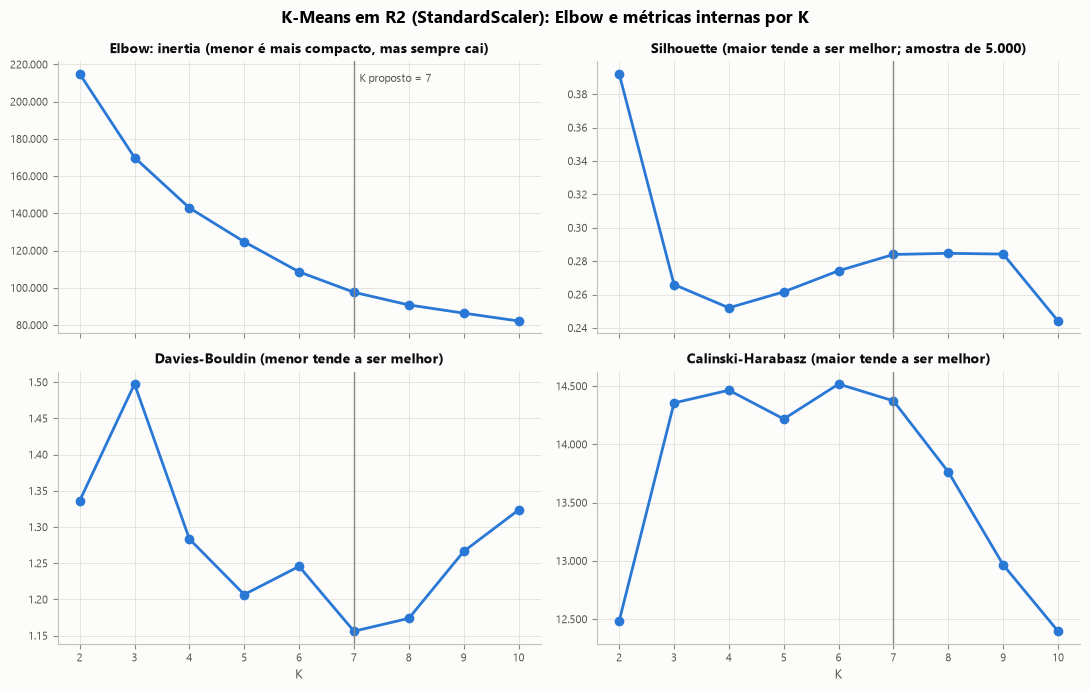

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
panels = [
    ("inertia", "Elbow: inertia (menor é mais compacto, mas sempre cai)"),
    ("silhouette", "Silhouette (maior tende a ser melhor; amostra de 5.000)"),
    ("davies_bouldin", "Davies-Bouldin (menor tende a ser melhor)"),
    ("calinski_harabasz", "Calinski-Harabasz (maior tende a ser melhor)"),
]
for ax, (column, title) in zip(axes.flat, panels):
    ax.plot(sweep.index, sweep[column], color=plots.SERIES_COLORS[0], marker="o", markersize=6)
    ax.axvline(config.FINAL_K, color=plots.INK_MUTED, linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(config.K_RANGE)
    if column in ("inertia", "calinski_harabasz"):
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: plots.fmt_int(value)))
for ax in axes[1]:
    ax.set_xlabel("K")
axes[0, 0].text(config.FINAL_K + 0.1, sweep["inertia"].max(), f"K proposto = {config.FINAL_K}",
                fontsize=8, color=plots.INK_SECONDARY, va="top")
fig.suptitle("K-Means em R2 (StandardScaler): Elbow e métricas internas por K", fontsize=12, fontweight="bold")
fig.tight_layout()
plots.save_figure(fig, "kmeans_k_selection")
plt.show()

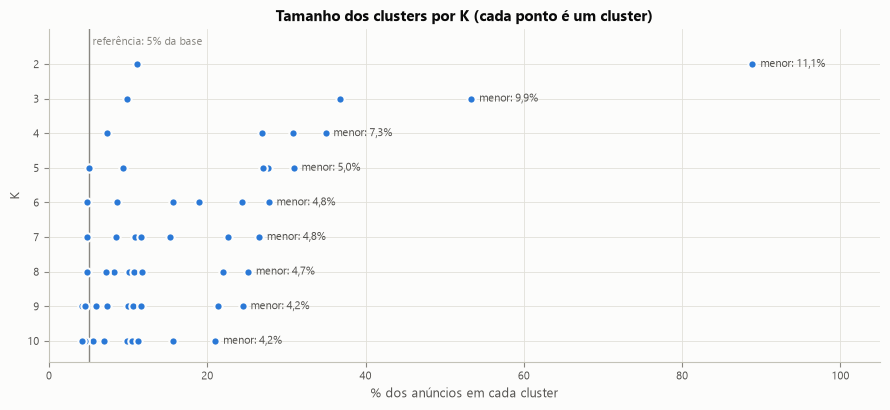

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for k in config.K_RANGE:
    shares = evaluation.cluster_sizes(labels_by_k[k]) / len(listings) * 100
    ax.scatter(shares, np.full(len(shares), k), s=36, color=plots.SERIES_COLORS[0], edgecolor=plots.SURFACE, linewidth=1.5, zorder=3)
    ax.text(shares.max() + 1, k, f"menor: {shares.min():.1f}%".replace(".", ","), va="center", fontsize=8, color=plots.INK_SECONDARY)
ax.axvline(5, color=plots.INK_MUTED, linewidth=1)
ax.text(5.5, 1.35, "referência: 5% da base", fontsize=8, color=plots.INK_MUTED, va="center")
ax.set_yticks(config.K_RANGE)
ax.set_ylim(10.6, 1.0)
ax.set_xlim(0, 105)
ax.set_xlabel("% dos anúncios em cada cluster")
ax.set_ylabel("K")
ax.set_title("Tamanho dos clusters por K (cada ponto é um cluster)")
fig.tight_layout()
plots.save_figure(fig, "kmeans_cluster_sizes")
plt.show()

In [12]:
stability = pd.DataFrame([evaluation.seed_stability(X_b, k) for k in config.K_RANGE]).set_index("k")
stability.to_csv(config.REPORTS_DIR / "kmeans_seed_stability.csv")
stability

,ari_mean,ari_min
k,,
2,0.994,0.989
3,0.999,0.998
4,0.998,0.995
5,0.970,0.946
6,0.994,0.989
7,0.996,0.992
8,0.996,0.993
9,0.990,0.980
10,0.848,0.703


### 5.1 Candidatos lado a lado

As métricas não apontam para o mesmo K. Antes de decidir, comparo os perfis dos candidatos em unidades de negócio (valores
originais, sem log). A composição por `room_type` é parte da **definição** dos grupos, porque `room_type` entrou na representação.

In [13]:
candidate_columns = ["n_listings", "pct_listings", "price_q1", "price_median", "price_q3", "minimum_nights_median",
                     "pct_minimum_nights_30plus", "availability_365_median", "pct_availability_zero",
                     "reviews_per_month_median", "host_listings_median"]
for k in config.CANDIDATE_KS:
    frame = listings.assign(cluster=labels_by_k[k])
    table = profiling.profile_table(frame, "cluster")[candidate_columns].join(
        profiling.composition_table(frame, "cluster", "room_type", config.ROOM_TYPE_ORDER)
        .drop(index="Base geral").add_prefix("% "))
    print(f"\n=== K = {k} ===")
    display(table.round(2))


=== K = 5 ===


,n_listings,pct_listings,price_q1,price_median,price_q3,minimum_nights_median,pct_minimum_nights_30plus,availability_365_median,pct_availability_zero,reviews_per_month_median,host_listings_median,% Entire home/apt,% Private room,% Shared room
cluster,,,,,,,,,,,,,,
0,4566,9.340,65.000,100.000,150.000,30.000,60.380,179.000,18.940,0.150,1.000,57.530,39.380,3.090
1,13523,27.660,50.000,65.000,85.000,2.000,0.000,0.000,59.470,0.140,1.000,4.240,92.130,3.630
2,15111,30.910,130.000,180.000,250.000,3.000,0.090,0.000,53.700,0.180,1.000,94.590,4.900,0.520
3,2459,5.030,120.000,187.000,250.000,30.000,70.440,325.000,1.870,0.050,52.000,77.800,20.780,1.420
4,13225,27.050,68.000,99.000,150.000,2.000,0.020,210.000,3.490,2.690,1.000,45.380,51.500,3.120



=== K = 7 ===

,n_listings,pct_listings,price_q1,price_median,price_q3,minimum_nights_median,pct_minimum_nights_30plus,availability_365_median,pct_availability_zero,reviews_per_month_median,host_listings_median,% Entire home/apt,% Private room,% Shared room
cluster,,,,,,,,,,,,,,
0,7490,15.320,60.000,85.000,120.000,2.000,0.010,66.000,10.800,3.160,1.000,37.840,59.170,2.990
1,11034,22.570,50.000,65.000,89.000,2.000,0.000,0.000,68.860,0.100,1.000,2.490,94.300,3.210
2,2325,4.760,125.000,189.000,250.000,30.000,74.150,322.000,1.980,0.050,65.000,81.980,17.030,0.990
3,12969,26.530,122.000,165.000,225.000,3.000,0.020,0.000,63.690,0.150,1.000,95.370,4.090,0.540
4,5282,10.810,52.000,70.000,99.000,2.000,0.000,325.000,0.000,0.880,2.000,4.880,88.530,6.590
5,4123,8.430,65.000,100.000,150.000,30.000,66.580,157.000,19.650,0.140,1.000,59.520,37.550,2.930
6,5661,11.580,160.000,220.000,325.000,2.000,0.580,269.000,0.120,1.590,1.000,93.820,5.860,0.320


**Leitura e proposta de K.**

As métricas **divergem**, o que é esperado:

- **Silhouette:** o máximo está em K = 2 (0,392), mas essa solução põe 88,9% dos anúncios num grupo e 11,1% no outro. É a
  situação da pergunta de revisão do enunciado: Silhouette maior, segmentação inútil, porque quase toda a base cai num grupo só.
  Entre K = 3 e 10, o Silhouette sobe até um patamar em K = 7–9 (0,284–0,285) e cai em K = 10 (0,244).
- **Davies-Bouldin:** o mínimo está em **K = 7** (1,156), seguido de K = 8 (1,174).
- **Calinski-Harabasz:** o máximo está em K = 6 (14.518). K = 7 fica 1% abaixo (14.373), e o índice cai rápido a partir de K = 8.
- **Elbow:** a queda relativa da inertia passa de 10,1% (6 → 7) para 7,0% (7 → 8) e 4,8% (8 → 9). A curva perde força depois de
  K = 7, mas não há cotovelo nítido.
- **Tamanho dos grupos:** a partir de K = 5, o menor cluster tem cerca de 5% da base. Em K = 7 são 4,8% (2.325 anúncios), ainda o
  bastante para uma ação dedicada.
- **Robustez:** com 5 sementes diferentes, as partições de K = 2 a 9 são praticamente idênticas (ARI médio ≥ 0,97). K = 5 é o
  menos estável da faixa (0,970; mínimo 0,946), e K = 10 é instável (0,848; mínimo 0,703).

**Proposta: K = 7.** É onde as métricas mais convergem: melhor Davies-Bouldin, Silhouette no patamar, Calinski-Harabasz 1% abaixo
do máximo e Elbow perdendo força. A partição também é estável (ARI 0,996), e nenhum grupo é minúsculo. Na tabela de candidatos,
os sete grupos são distintos em unidades de negócio:

- **H2 e H3 aparecem juntas**, em dois grupos de estadia longa:
  - cluster 2 (4,8%): 30 noites, anfitriões com mediana de 65 anúncios, 322 dias disponíveis e quase nenhuma avaliação
    (0,05/mês);
  - cluster 5 (8,4%): também 30 noites, mas com anfitrião de 1 anúncio e disponibilidade mediana de 157 dias.
- **O grupo ativo se divide em três:**
  - alta atividade com disponibilidade moderada (cluster 0: 3,16 avaliações/mês, 66 dias);
  - quartos privados com alta disponibilidade (cluster 4: 325 dias);
  - imóveis inteiros de preço mais alto e alta disponibilidade (cluster 6: mediana de US$ 220, 269 dias).
- **Os dois maiores grupos** são quartos privados (cluster 1) e imóveis inteiros (cluster 3) com disponibilidade declarada mediana
  zero e pouca atividade (0,10 e 0,15 avaliações/mês). Eles se relacionam com a H4.

**Alternativa mais simples: K = 5.** Mantém os dois grupos de estadia longa e os dois de disponibilidade zero, mas junta num único
grupo ativo anúncios de tipos e disponibilidades diferentes. Perde a distinção entre "alta atividade" e "imóvel inteiro de preço
alto e alta disponibilidade", e tem métricas e estabilidade piores.

Os segmentos só recebem nome na Fase 3, depois dos gráficos de distribuição, PCA e mapa.

In [14]:
k_final = config.FINAL_K
final_labels = labels_by_k[k_final]
final_frame = listings.assign(cluster=final_labels)
final_profile = profiling.profile_table(final_frame, "cluster")
final_profile.to_csv(config.REPORTS_DIR / f"kmeans_k{k_final}_profile_preliminary.csv")
room_comp = profiling.composition_table(final_frame, "cluster", "room_type", config.ROOM_TYPE_ORDER)
group_comp = profiling.composition_table(final_frame, "cluster", "neighbourhood_group", config.NEIGHBOURHOOD_GROUP_ORDER)
display(room_comp.round(1))
group_comp.round(1)

room_type,Entire home/apt,Private room,Shared room
cluster,,,
0,37.800,59.200,3.000
1,2.500,94.300,3.200
2,82.000,17.000,1.000
3,95.400,4.100,0.500
4,4.900,88.500,6.600
5,59.500,37.500,2.900
6,93.800,5.900,0.300
Base geral,52.000,45.700,2.400


neighbourhood_group,Manhattan,Brooklyn,Queens,Bronx,Staten Island
cluster,,,,,
0,36.000,41.500,17.700,3.800,1.100
1,34.700,50.900,11.600,2.300,0.500
2,83.200,9.700,7.000,0.000,0.000
3,53.300,39.300,6.300,0.800,0.300
4,27.000,42.600,22.400,5.600,2.300
5,47.900,41.600,8.500,1.400,0.500
6,50.900,36.700,9.800,1.600,1.000
Base geral,44.300,41.100,11.600,2.200,0.800


**Leitura (K = 7, preliminar).**

- **Distritos:** `neighbourhood_group` **não** entrou em R2, então a composição por distrito é uma comparação descritiva, e não
  tautológica. A maioria dos clusters fica próxima da composição da base, com duas exceções:
  - o cluster de estadia longa com anfitriões de portfólio grande (cluster 2) tem **83,2% dos anúncios em Manhattan**, contra 44,3%
    na base;
  - os quartos privados com alta disponibilidade (cluster 4) pesam mais em Queens (22,4%, contra 11,6% na base).
- **`room_type`:** entrou na definição dos grupos, então sua composição é parte da definição, e não validação. Quatro clusters são
  quase puros (≥ 88% de um tipo). Três têm composição mais misturada: os clusters 0, 5 e 2, com 59%, 60% e 82% do tipo
  predominante.

## 6. Representações alternativas (comparação)

Mesmo K proposto, mesmo protocolo, mesmas linhas. Os índices de cada representação são calculados **no próprio espaço** e
**não** são diretamente comparáveis entre representações: cada espaço tem dimensões e escalas diferentes, e o enunciado proíbe
comparar inertias brutas entre espaços distintos. O que se compara aqui é a **estrutura** dos grupos, por meio do ARI contra R2 e
da composição dos clusters.

In [15]:
alternatives = []
alt_labels = {}
for representation in ["R1", "R2", "R3"]:
    X_rep = preprocessing.make_preprocessor(representation, scale=True).fit_transform(listings)
    model = KMeans(n_clusters=k_final, **config.KMEANS_PARAMS).fit(X_rep)
    alt_labels[representation] = model.labels_
    metrics = evaluation.internal_metrics(X_rep, model.labels_, silhouette_idx)
    sizes = evaluation.cluster_sizes(model.labels_) / len(listings) * 100
    alternatives.append({
        "representação": representation,
        "dimensões": X_rep.shape[1],
        "silhouette": metrics["silhouette"],
        "davies_bouldin": metrics["davies_bouldin"],
        "calinski_harabasz": metrics["calinski_harabasz"],
        "menor cluster %": sizes.min(),
        "ARI vs R2": adjusted_rand_score(model.labels_, final_labels),
    })
alternatives = pd.DataFrame(alternatives).set_index("representação")
alternatives.to_csv(config.REPORTS_DIR / "kmeans_representations.csv")
alternatives

,dimensões,silhouette,davies_bouldin,calinski_harabasz,menor cluster %,ARI vs R2
representação,,,,,,
R1,5,0.264,1.178,"15,812.367",4.807,0.705
R2,8,0.284,1.156,"14,373.435",4.756,1.000
R3,13,0.230,1.332,"11,178.194",4.713,0.951


In [16]:
for representation in ["R1", "R3"]:
    frame = listings.assign(cluster=alt_labels[representation])
    print(f"\n=== {representation}: composição por neighbourhood_group e room_type (% dentro do cluster) ===")
    display(profiling.composition_table(frame, "cluster", "neighbourhood_group", config.NEIGHBOURHOOD_GROUP_ORDER).round(1)
            .join(profiling.composition_table(frame, "cluster", "room_type", config.ROOM_TYPE_ORDER).round(1)))


=== R1: composição por neighbourhood_group e room_type (% dentro do cluster) ===


,Manhattan,Brooklyn,Queens,Bronx,Staten Island,Entire home/apt,Private room,Shared room
cluster,,,,,,,,
0,37.100,41.900,16.500,3.500,1.000,44.800,52.900,2.300
1,82.600,10.200,7.100,0.000,0.000,81.100,17.700,1.100
2,56.900,33.300,7.900,1.200,0.600,86.500,13.100,0.400
3,59.200,35.100,4.900,0.500,0.200,85.500,13.900,0.600
4,47.500,42.200,8.500,1.400,0.500,57.900,39.400,2.700
5,24.300,44.100,23.200,5.900,2.600,16.400,77.200,6.400
6,31.800,53.100,12.300,2.300,0.600,22.200,74.700,3.100
Base geral,44.300,41.100,11.600,2.200,0.800,52.000,45.700,2.400



=== R3: composição por neighbourhood_group e room_type (% dentro do cluster) ===


,Manhattan,Brooklyn,Queens,Bronx,Staten Island,Entire home/apt,Private room,Shared room
cluster,,,,,,,,
0,35.400,42.000,17.800,3.800,1.000,39.300,57.900,2.800
1,33.100,52.700,11.400,2.300,0.500,3.700,93.100,3.200
2,54.900,38.000,6.000,0.800,0.300,94.700,4.800,0.500
3,53.600,34.800,9.200,1.500,1.000,92.800,6.800,0.300
4,25.100,43.300,23.400,5.800,2.400,6.000,87.400,6.600
5,84.800,8.700,6.500,0.000,0.000,82.900,16.100,1.000
6,47.600,41.700,8.700,1.400,0.500,58.900,38.200,2.900
Base geral,44.300,41.100,11.600,2.200,0.800,52.000,45.700,2.400


**Leitura** (mesmo K = 7; os índices de cada espaço não são comparáveis entre si).

- **R1 (sem `room_type`):** reproduz boa parte da estrutura de R2 (ARI 0,705). Vários clusters ainda se separam por tipo de imóvel
  (de 75% a 87% de um único tipo), porque preço e tipo andam juntos. Incluir `room_type` deixa explícito um corte que as numéricas
  já sugerem.
- **R3 (+ `neighbourhood_group`):** a partição quase não muda (ARI 0,951 contra R2), e nenhum cluster vira um recorte por distrito.
  O único concentrado em Manhattan (84,8%) é o mesmo de estadia longa com anfitriões de portfólio grande, que já existe em R2.
  Incluir a geografia não acrescenta segmentos: só adiciona cinco dummies e torna tautológica a comparação posterior com o distrito.

**Conclusão:** R2 continua como representação principal, e `neighbourhood_group` fica como variável de comparação, fora da
definição dos grupos.

### Resumo da parte 1 (aprovado no Checkpoint 2, em 2026-10-21)

1. **Normalização:**
   - sem scaling, `availability_365` responde por 99,98% da distância, e o K-Means só fatia a disponibilidade, mesmo com Silhouette
     de 0,73;
   - com `StandardScaler`, cada numérica pesa 18,1% e `room_type`, 9,4%;
   - as partições dos dois cenários quase não concordam (ARI 0,15);
   - **decisão: cenário B.**
2. **Categóricas:** pesam pouco na média, mas uma diferença de `room_type` vale √2. A comparação com `room_type` não é validação
   independente.
3. **K = 7** (aprovado), com K = 5 como alternativa mais simples (justificativa na seção 5).
4. **Representação:** R2 se mantém. R3 não muda a estrutura (ARI 0,951), e R1 perde a separação explícita por tipo.

## 7. DBSCAN

### 7.1 Conceitos

O DBSCAN define cluster por **densidade**, não por centro:

- **Vizinhança de raio `eps`:** os pontos a até `eps` de distância (Euclidiana, no mesmo espaço R2-B).
- **Ponto core:** tem pelo menos `min_samples` pontos na vizinhança, contando ele mesmo.
- **Ponto border:** não é core, mas está na vizinhança de um core. Entra no cluster desse core.
- **Ruído (rótulo −1):** nem core nem alcançável a partir de um core. **Não é um segmento**: é o que sobra fora das regiões densas.
- **Cluster:** um conjunto de cores conectados (um core na vizinhança do outro), mais os borders ligados a eles.

Diferente do K-Means, o DBSCAN **não recebe K**. O número de grupos resulta de `eps` e `min_samples`:

- **`eps` maior:** vizinhanças maiores, mais pontos core, grupos que se fundem e menos ruído. Acima da distância que separa as
  regiões densas, tudo vira **um único grupo**.
- **`eps` menor:** vizinhanças menores. Abaixo da distância típica entre vizinhos, quase tudo vira **só ruído**.
- **`min_samples` maior:** exige mais densidade para um ponto ser core. Há menos cores, mais ruído, e grupos pequenos ou esparsos
  deixam de existir.
- **Vários grupos** só aparecem quando há regiões densas separadas por "vales" de baixa densidade mais largos que `eps`.

**Centróide × densidade.** O K-Means resume cada grupo por uma média e atribui **todos** os pontos ao centro mais próximo. Por
isso tende a formar grupos convexos de tamanho parecido e cobre 100% da base. O DBSCAN não tem centro: segue a continuidade da
densidade, aceita formatos arbitrários e deixa pontos isolados como ruído.

**Inferência.** O `DBSCAN` do scikit-learn só tem `fit` e `fit_predict` e devolve `labels_` para os dados do ajuste. Não existe
`predict` para anúncios novos, e este projeto **não simula** um.

### 7.2 Amostra e representatividade

O enunciado permite uma amostra reprodutível de 8.000 a 12.000 linhas, por causa do custo de memória. Uso **10.000 anúncios**,
sorteados sem reposição com a semente 42, no **mesmo espaço R2-B** do K-Means: o pré-processador ajustado na base inteira é
reaplicado à amostra.

In [17]:
dbscan_idx = evaluation.fixed_sample_indices(len(listings), config.DBSCAN_SAMPLE_SIZE)
sample = listings.iloc[dbscan_idx].reset_index(drop=True)
X_s = X_b[dbscan_idx]
sample_sil_idx = evaluation.fixed_sample_indices(len(sample), config.SILHOUETTE_SAMPLE_SIZE)
print(f"amostra DBSCAN: {len(sample):,} anúncios | Silhouette dentro da amostra: {len(sample_sil_idx):,} pontos".replace(",", "."))
rep_categories, rep_quantiles = profiling.sample_representativeness(listings, sample)
rep_categories.to_csv(config.REPORTS_DIR / "dbscan_sample_representativeness_categories.csv")
rep_quantiles.to_csv(config.REPORTS_DIR / "dbscan_sample_representativeness_quantiles.csv")
display(rep_categories.round(2))
rep_quantiles.round(2)

amostra DBSCAN: 10.000 anúncios | Silhouette dentro da amostra: 5.000 pontos


pct_base  pct_sample  diff_pp
column              category                                      
room_type           Entire home/apt    51.970      51.600   -0.370
                    Private room       45.660      45.930    0.270
                    Shared room         2.370       2.470    0.100
neighbourhood_group Manhattan          44.310      43.940   -0.370
                    Brooklyn           41.110      41.550    0.440
                    Queens             11.590      11.440   -0.150
                    Bronx               2.230       2.340    0.110
                    Staten Island       0.760       0.730   -0.030

base  sample  diff_pct
column                         quantile                          
price                          0.250     69.000  69.000     0.000
                               0.500    106.000 105.000    -0.940
                               0.750    175.000 175.000     0.000
minimum_nights                 0.250      1.000   1.000     0.000
                               0.500      3.000   3.000     0.000
                               0.750      5.000   5.000     0.000
availability_365               0.250      0.000   0.000     0.000
                               0.500     45.000  42.000    -6.670
                               0.750    227.000 229.000     0.880
reviews_per_month              0.250      0.040   0.040     0.000
                               0.500      0.370   0.360    -2.700
                               0.750      1.580   1.540    -2.530
calculated_host_listings_count 0.250      1.000   1.000     0.000
                               0.500      1.000   1.000     0.000
                               0.750      2.000   2.000     0.000

**Leitura.** A amostra é representativa da base:

- **Categóricas:** a participação de cada `room_type` e `neighbourhood_group` difere da base em no máximo **0,44 ponto percentual**.
- **Numéricas:** os quartis coincidem, com duas pequenas exceções:
  - a mediana de `availability_365` é 42 dias na amostra, contra 45 na base;
  - a de `reviews_per_month` é 0,36, contra 0,37.
- **Mesma estrutura:** na seção 7.7, o K-Means reajustado só na amostra reproduz a partição do K-Means da base inteira (ARI 0,97).

10.000 linhas ainda deixam grupos pequenos visíveis: um grupo com 1% da base teria cerca de 100 anúncios na amostra.

### 7.3 Distância ao k-ésimo vizinho

Com `min_samples = k`, um ponto é core quando a distância ao seu k-ésimo vizinho é ≤ `eps`. Ordenando essas distâncias, a curva
mostra que fração da amostra seria core para cada `eps`.

Duas referências no gráfico:

- **`eps` de referência (0,9):** fica perto do p90 da curva com k = 16. O `min_samples = 16` segue a regra prática de 2 × o número
  de dimensões (8 em R2).
- **√2 ≈ 1,41:** a menor distância possível entre anúncios de `room_type` diferentes. Abaixo dela, nenhum cluster pode misturar
  tipos de imóvel.

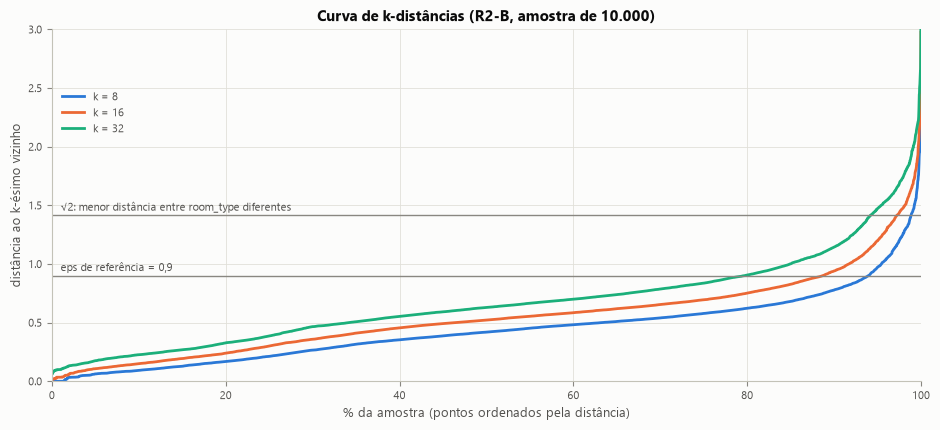

,p50,p75,p90,p95,p99
k = 8,0.419,0.578,0.778,0.972,1.440
k = 16,0.521,0.695,0.940,1.197,1.666
k = 32,0.630,0.837,1.145,1.471,1.968


In [18]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
kdist_rows = {}
for color, k in zip(plots.SERIES_COLORS, config.DBSCAN_MIN_SAMPLES_GRID):
    distances = evaluation.kth_neighbor_distances(X_s, k)
    kdist_rows[f"k = {k}"] = np.quantile(distances, [0.50, 0.75, 0.90, 0.95, 0.99])
    ax.plot(np.arange(len(distances)) / len(distances) * 100, distances, color=color, label=f"k = {k}")
ax.axhline(config.DBSCAN_REFERENCE["eps"], color=plots.INK_MUTED, linewidth=1)
ax.text(1, config.DBSCAN_REFERENCE["eps"] + 0.04, "eps de referência = 0,9", fontsize=8, color=plots.INK_SECONDARY)
ax.axhline(np.sqrt(2), color=plots.INK_MUTED, linewidth=1)
ax.text(1, np.sqrt(2) + 0.04, "√2: menor distância entre room_type diferentes", fontsize=8, color=plots.INK_SECONDARY)
ax.set_ylim(0, 3)
ax.set_xlim(0, 100)
ax.set_xlabel("% da amostra (pontos ordenados pela distância)")
ax.set_ylabel("distância ao k-ésimo vizinho")
ax.set_title("Curva de k-distâncias (R2-B, amostra de 10.000)")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.85))
fig.tight_layout()
plots.save_figure(fig, "dbscan_k_distance")
plt.show()
pd.DataFrame(kdist_rows, index=["p50", "p75", "p90", "p95", "p99"]).T

### 7.4 Grade de `eps` × `min_samples` (R2-B)

Para cada combinação, registro:

- número de clusters (e quantos têm pelo menos 1% da amostra);
- pontos core, border e ruído, e o percentual de ruído;
- tamanho do maior cluster;
- métricas **só nos pontos não ruído**, com a cobertura avaliada. Com menos de 2 clusters, a métrica é "não aplicável".

In [19]:
grid_r2, grid_labels_r2 = evaluation.dbscan_grid(X_s, silhouette_idx=sample_sil_idx)
grid_r2.to_csv(config.REPORTS_DIR / "dbscan_grid_r2.csv", index=False)
grid_r2

,eps,min_samples,n_clusters,n_clusters_ge_1pct,n_core,n_border,n_noise,pct_noise,largest_cluster_pct,coverage,silhouette,davies_bouldin,calinski_harabasz,metrics_note
0,0.300,8,38,6,3359,611,6030,60.300,11.480,0.397,-0.060,1.084,458.429,None
1,0.300,16,12,6,2492,537,6971,69.710,9.580,0.303,0.136,1.398,"1,198.834",None
2,0.300,32,6,6,1797,601,7602,76.020,7.430,0.240,0.197,1.784,"1,543.714",None
3,0.500,8,22,3,6313,1329,2358,23.580,37.580,0.764,-0.058,0.867,342.459,None
4,0.500,16,13,4,4646,1538,3816,38.160,31.540,0.618,0.171,0.903,706.020,None
5,0.500,32,4,2,3408,1147,5445,54.450,25.370,0.456,0.378,0.738,"1,977.029",None
6,0.700,8,13,2,8614,645,741,7.410,47.300,0.926,0.006,0.835,311.257,None
7,0.700,16,10,3,7555,1278,1167,11.670,42.850,0.883,0.096,1.043,726.179,None
8,0.700,32,4,3,6008,1998,1994,19.940,39.930,0.801,0.264,1.202,"1,879.195",None
9,0.900,8,12,2,9395,299,306,3.060,50.140,0.969,-0.016,0.977,258.980,None


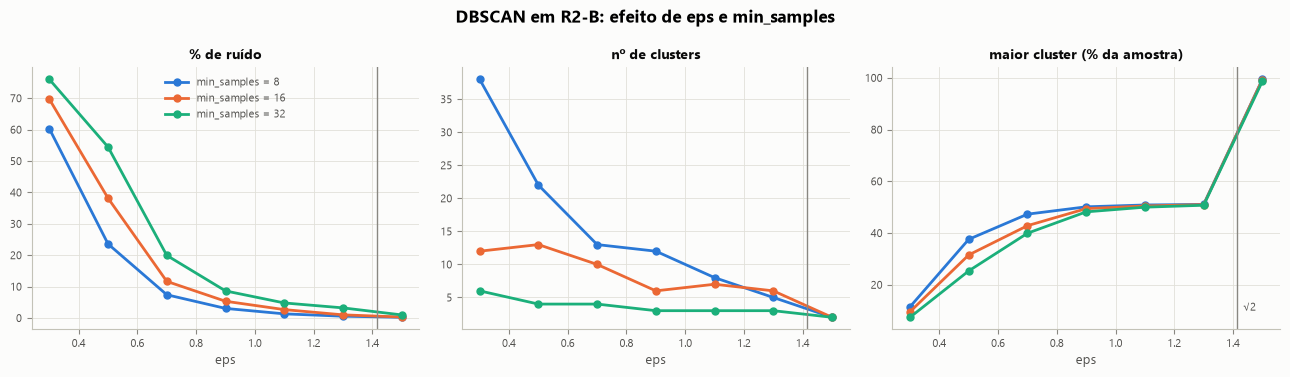

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [("pct_noise", "% de ruído"), ("n_clusters", "nº de clusters"), ("largest_cluster_pct", "maior cluster (% da amostra)")]
for ax, (column, title) in zip(axes, panels):
    for color, min_samples in zip(plots.SERIES_COLORS, config.DBSCAN_MIN_SAMPLES_GRID):
        part = grid_r2[grid_r2["min_samples"] == min_samples]
        ax.plot(part["eps"], part[column], color=color, marker="o", markersize=5, label=f"min_samples = {min_samples}")
    ax.axvline(np.sqrt(2), color=plots.INK_MUTED, linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("eps")
axes[0].legend()
axes[2].text(np.sqrt(2) + 0.02, 10, "√2", ha="left", fontsize=8, color=plots.INK_SECONDARY)
fig.suptitle("DBSCAN em R2-B: efeito de eps e min_samples", fontsize=12, fontweight="bold")
fig.tight_layout()
plots.save_figure(fig, "dbscan_grid_r2")
plt.show()

**Leitura da curva e da grade.**

- **Curva de k-distâncias:** fica quase plana até cerca de 90% dos pontos e sobe rápido depois. Com k = 16, o p90 é 0,94 e o p99 é
  1,67. Não há um "joelho" nítido que separe regiões densas, primeiro sinal de que a base é um contínuo.
- **`eps` ≤ 0,5:** o DBSCAN fragmenta. Com `eps = 0,3` aparecem de 6 a 38 clusters e de 60% a 76% de ruído.
- **`eps` de 0,7 a 1,3:** o ruído cai para 0,6%–20% e surgem **dois grupos grandes**, o maior com 40% a 51% da amostra. Como mostra
  a seção 7.5, eles são os dois tipos principais de imóvel.
- **`eps` = 1,5 (acima de √2):** os tipos se fundem e um único grupo reúne 98,7% a 99,4% da amostra. O Silhouette sobe para cerca
  de 0,52, mas porque separa esse grupo gigante de um grupo minúsculo, mesmo caso do K = 2 do K-Means. Índice alto, solução inútil.
- **`min_samples` maior aumenta o ruído:** com `eps = 0,5`, o ruído vai de 23,6% (8) a 38,2% (16) e 54,5% (32).

Nenhuma combinação da grade produz vários grupos grandes com pouco ruído. Ou o DBSCAN fragmenta em ruído, ou separa os tipos de
imóvel, ou junta tudo.

### 7.5 Configuração de referência e configuração fina

A **referência** (`eps = 0,9`, `min_samples = 16`) segue a regra prática descrita na seção 7.3. A **configuração fina**
(`eps = 0,5`, `min_samples = 16`) serve para ver quais grupos densos pequenos existem antes de tudo se fundir. Em ambas, o ruído
aparece como linha separada e **não** é tratado como segmento.

In [21]:
reference_model = DBSCAN(**config.DBSCAN_REFERENCE).fit(X_s)
reference_labels = reference_model.labels_
print("referência:", config.DBSCAN_REFERENCE, evaluation.dbscan_point_types(reference_model))
reference_groups, groups_order = profiling.dbscan_groups(reference_labels)
reference_frame = sample.assign(dbscan_label=reference_labels, dbscan_group=reference_groups)
reference_profile = profiling.profile_table(reference_frame, "dbscan_group", groups_order).join(
    profiling.composition_table(reference_frame, "dbscan_group", "room_type", config.ROOM_TYPE_ORDER).add_prefix("% "))
reference_profile.to_csv(config.REPORTS_DIR / "dbscan_reference_profile.csv")
non_noise = reference_labels != -1
room_codes = sample["room_type"].map({r: i for i, r in enumerate(config.ROOM_TYPE_ORDER)}).to_numpy()
print("ARI entre os clusters do DBSCAN (sem ruído) e room_type:",
      round(adjusted_rand_score(reference_labels[non_noise], room_codes[non_noise]), 3))
reference_profile.round(2)

referência: {'eps': 0.9, 'min_samples': 16} {'n_core': 8868, 'n_border': 598, 'n_noise': 534}
ARI entre os clusters do DBSCAN (sem ruído) e room_type: 0.993


,n_listings,pct_listings,price_q1,price_median,price_q3,minimum_nights_median,pct_minimum_nights_30plus,availability_365_q1,availability_365_median,availability_365_q3,pct_availability_zero,number_of_reviews_median,reviews_per_month_median,host_listings_median,% Entire home/apt,% Private room,% Shared room
dbscan_group,,,,,,,,,,,,,,,,,
cluster 0,4394,43.940,51.250,70.000,95.000,2.000,4.190,0.000,36.000,189.750,38.620,5.000,0.390,1.000,0.000,100.000,0.000
cluster 1,4944,49.440,120.000,160.000,225.000,3.000,11.550,0.000,33.500,219.000,36.730,5.000,0.320,1.000,100.000,0.000,0.000
clusters < 1%,128,1.280,37.000,52.500,101.250,2.000,16.410,0.000,291.000,342.250,29.690,3.000,0.290,3.000,22.660,0.000,77.340
ruído (-1),534,5.340,49.000,100.000,280.750,4.000,31.270,53.000,204.000,331.750,12.550,5.000,0.680,5.000,35.020,37.270,27.720


In [22]:
fine_labels = grid_labels_r2[(config.DBSCAN_FINE["eps"], config.DBSCAN_FINE["min_samples"])]
fine_groups, fine_order = profiling.dbscan_groups(fine_labels)
fine_frame = sample.assign(dbscan_label=fine_labels, dbscan_group=fine_groups)
fine_profile = profiling.profile_table(fine_frame, "dbscan_group", fine_order).join(
    profiling.composition_table(fine_frame, "dbscan_group", "room_type", config.ROOM_TYPE_ORDER).add_prefix("% "))
print("configuração fina:", config.DBSCAN_FINE, "| clusters:", len(set(fine_labels) - {-1}),
      f"| ruído: {(fine_labels == -1).mean():.1%}")
small = fine_frame[fine_frame["dbscan_group"] == "clusters < 1%"]
print("clusters < 1%: medianas de host_listings por cluster:",
      small.groupby("dbscan_label")["calculated_host_listings_count"].median().astype(int).tolist())
fine_profile[["n_listings", "pct_listings", "price_median", "minimum_nights_median", "availability_365_median",
              "reviews_per_month_median", "host_listings_median", "% Entire home/apt", "% Private room"]].round(2)

configuração fina: {'eps': 0.5, 'min_samples': 16} | clusters: 13 | ruído: 38.2%
clusters < 1%: medianas de host_listings por cluster: [1, 1, 1, 9, 3, 1, 1, 232, 327]


,n_listings,pct_listings,price_median,minimum_nights_median,availability_365_median,reviews_per_month_median,host_listings_median,% Entire home/apt,% Private room
dbscan_group,,,,,,,,,
cluster 0,2458,24.580,70.000,2.000,0.000,0.150,1.000,0.000,100.000
cluster 1,3154,31.540,150.000,3.000,0.000,0.270,1.000,100.000,0.000
cluster 3,141,1.410,76.000,1.000,358.000,0.180,1.000,0.000,100.000
cluster 7,154,1.540,190.000,30.000,341.000,0.040,87.000,100.000,0.000
clusters < 1%,277,2.770,195.000,3.000,333.000,0.210,3.000,73.290,26.710
ruído (-1),3816,38.160,100.000,3.000,203.500,0.850,2.000,43.210,50.310


**Leitura.**

**Configuração de referência** (`eps = 0,9`, `min_samples = 16`): 6 clusters, com 8.868 pontos core, 598 border e **534 de ruído
(5,3%)**, ou seja, cobertura de 94,7%.

- **Os grupos são `room_type`:** o cluster 0 (43,9%) é 100% quartos privados, o cluster 1 (49,4%) é 100% imóveis inteiros, e os
  clusters menores somam 1,3% (77% quartos compartilhados). O ARI entre os clusters não ruído e `room_type` é **0,993**. Com
  `eps` < √2, nenhum cluster pode misturar tipos, e dentro de cada tipo a densidade é contínua o bastante para virar um grupo só.
  É uma separação **tautológica**, que nada acrescenta à coluna original.
- **Heterogeneidade escondida:** dentro de cada grupo, o intervalo interquartil da disponibilidade vai de 0 a 190–219 dias.
  Isso explica o Silhouette sem ruído quase nulo (0,018).
- **O ruído é o anúncio atípico, não um segmento:**
  - disponibilidade declarada mediana de 204 dias, contra 34–36 nos clusters;
  - 31% com estadia mínima de 30 noites ou mais, contra 4%–12%;
  - 28% de quartos compartilhados;
  - anfitriões com mediana de 5 anúncios.

**Configuração fina** (`eps = 0,5`): 13 clusters e **38,2% de ruído**.

- **Núcleos densos:** os dois maiores são quartos privados (24,6%) e imóveis inteiros (31,5%) com disponibilidade declarada zero.
  É a massa de anúncios parecidos e pouco ativos.
- **Grupos densos pequenos:** quartos privados disponíveis o ano todo (1,4%), imóveis inteiros de 30 noites de anfitriões com
  mediana de 87 anúncios (1,5%) e, entre os clusters abaixo de 1%, grupos cujo anfitrião tem 232 e 327 anúncios.
- **O que essa densidade mostra:** anúncios quase idênticos de um mesmo operador, não segmentos comerciais. A cobertura é de só
  62%.

### 7.6 Experimento complementar: DBSCAN só com as numéricas (R1)

Sem as dummies de `room_type`, a densidade passa a refletir só o perfil numérico. Este experimento é **complementar**: os índices
dele vêm de outro espaço e **não** são comparados diretamente com o K-Means em R2.

In [23]:
prep_r1 = preprocessing.make_preprocessor("R1", scale=True).fit(listings)
X_s_r1 = prep_r1.transform(sample)
grid_r1, grid_labels_r1 = evaluation.dbscan_grid(X_s_r1, silhouette_idx=sample_sil_idx)
grid_r1.to_csv(config.REPORTS_DIR / "dbscan_grid_r1_numeric.csv", index=False)
grid_r1[["eps", "min_samples", "n_clusters", "n_clusters_ge_1pct", "pct_noise", "largest_cluster_pct",
         "silhouette", "davies_bouldin", "metrics_note"]]

,eps,min_samples,n_clusters,n_clusters_ge_1pct,pct_noise,largest_cluster_pct,silhouette,davies_bouldin,metrics_note
0,0.300,8,37,3,54.780,19.620,-0.257,1.066,NaN
1,0.300,16,12,3,65.210,15.690,-0.086,1.351,NaN
2,0.300,32,4,3,72.850,12.960,0.106,2.052,NaN
3,0.500,8,18,3,17.560,77.380,-0.187,0.827,NaN
4,0.500,16,9,2,31.160,64.910,0.015,0.734,NaN
5,0.500,32,4,2,47.470,50.090,0.355,0.676,NaN
6,0.700,8,8,1,4.670,93.840,0.177,0.578,NaN
7,0.700,16,4,1,8.070,90.780,0.355,0.496,NaN
8,0.700,32,3,2,15.230,81.680,0.538,0.712,NaN
9,0.900,8,5,1,1.510,97.800,0.342,0.567,NaN


**Leitura.** Sem as dummies, a densidade do perfil numérico é praticamente **um contínuo**:

- **`eps` ≥ 0,7:** um único cluster reúne de 82% a 99,6% da amostra.
- **`eps` ≤ 0,5:** o ruído vai de 17,6% a 72,9%.
- **Silhouette alto (chega a 0,54–0,56) com `eps` entre 0,9 e 1,5:** aparece nas soluções de "2 clusters" em que o segundo é
  minúsculo.
  É a mesma armadilha da seção anterior.
- **`eps = 0,9` e `eps = 1,1` com `min_samples = 32`:** sobra um único cluster, e as métricas são registradas como **não
  aplicáveis**.

Este experimento confirma que os clusters do DBSCAN em R2 vêm das dummies de `room_type`, e não de vales de densidade no perfil
comercial. Por ser de outro espaço, ele não é comparado com o K-Means.

### 7.7 Comparação justa K-Means × DBSCAN

Mesma amostra de 10.000 anúncios, mesmo espaço R2-B e mesma amostra interna para o Silhouette. Comparo quatro versões:

1. o K-Means final (ajustado na base inteira), aplicado aos pontos da amostra;
2. o K-Means reajustado só na amostra, com o mesmo K e o mesmo protocolo;
3. o DBSCAN de referência, avaliado **sem o ruído**;
4. o K-Means final avaliado **nos mesmos pontos não ruído** do DBSCAN, para que a cobertura seja idêntica.

In [24]:
final_model = KMeans(n_clusters=k_final, **config.KMEANS_PARAMS).fit(X_b)
assert (final_model.labels_ == final_labels).all()
km_sample = final_labels[dbscan_idx]
km_sample_refit = KMeans(n_clusters=k_final, **config.KMEANS_PARAMS).fit(X_s).labels_
km_on_dbscan_points = np.where(reference_labels == -1, -1, km_sample)
fair = pd.DataFrame({
    "K-Means final (base inteira), na amostra": evaluation.internal_metrics(X_s, km_sample, sample_sil_idx),
    "K-Means reajustado na amostra": evaluation.internal_metrics(X_s, km_sample_refit, sample_sil_idx),
    "DBSCAN referência (sem ruído)": evaluation.internal_metrics(X_s, reference_labels, sample_sil_idx, exclude_noise=True),
    "K-Means final nos pontos não ruído do DBSCAN": evaluation.internal_metrics(X_s, km_on_dbscan_points, sample_sil_idx,
                                                                                  exclude_noise=True),
}).T[["n_clusters", "n_evaluated", "coverage", "silhouette", "davies_bouldin", "calinski_harabasz"]]
fair.to_csv(config.REPORTS_DIR / "kmeans_vs_dbscan.csv")
display(fair)
print("ARI K-Means final x K-Means reajustado na amostra:", round(adjusted_rand_score(km_sample, km_sample_refit), 3))
print("ARI DBSCAN (sem ruído) x K-Means final:", round(adjusted_rand_score(reference_labels[non_noise], km_sample[non_noise]), 3))
noise_by_segment = (pd.crosstab(km_sample, reference_labels == -1, normalize="index")[True] * 100).rename("% ruído do DBSCAN")
noise_by_segment.index.name = "segmento K-Means"
noise_by_segment.to_frame().T

,n_clusters,n_evaluated,coverage,silhouette,davies_bouldin,calinski_harabasz
"K-Means final (base inteira), na amostra",7.000,"10,000.000",1.000,0.283,1.148,"3,009.773"
K-Means reajustado na amostra,7.000,"10,000.000",1.000,0.283,1.152,"3,012.740"
DBSCAN referência (sem ruído),6.000,"9,466.000",0.947,0.018,1.190,509.281
K-Means final nos pontos não ruído do DBSCAN,7.000,"9,466.000",0.947,0.299,1.084,"3,138.473"


ARI K-Means final x K-Means reajustado na amostra: 0.97
ARI DBSCAN (sem ruído) x K-Means final: 0.279


segmento K-Means,0,1,2,3,4,5,6
% ruído do DBSCAN,4.218,1.564,19.794,1.205,9.381,14.564,6.977


**Leitura.** Mesma amostra, mesmo espaço e mesma amostra interna de Silhouette.

| Versão | Cobertura | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|---|
| K-Means final, na amostra | 100% | 0,283 | 1,148 | 3.010 |
| DBSCAN de referência (sem ruído) | 94,7% | 0,018 | 1,190 | 509 |
| K-Means final, nos mesmos pontos não ruído | 94,7% | 0,299 | 1,084 | 3.138 |

- **Com cobertura idêntica, o K-Means é melhor nos três índices.** Ressalva: esses índices favorecem grupos compactos e convexos,
  que é justamente o objetivo do K-Means, então a comparação não é neutra. O argumento decisivo, porém, não é o índice: os grupos
  do DBSCAN são `room_type` (ARI 0,993).
- **As duas partições concordam pouco** (ARI 0,279). O DBSCAN separa por tipo de imóvel. O K-Means separa também por atividade,
  disponibilidade, estadia e portfólio.
- **O ruído do DBSCAN se concentra nos segmentos mais atípicos do K-Means:**
  - 19,8% do segmento 2 (estadia longa de operadores) e 14,6% do segmento 5 (estadia longa individual);
  - 9,4% do segmento 4 (quartos privados com alta disponibilidade);
  - só 1,2% e 1,6% dos segmentos 3 e 1 (disponibilidade quase nula).

O ruído é útil como **diagnóstico** de anúncios fora do padrão, mas não define segmentos. Além disso, o DBSCAN não tem `predict`.

## 8. Segmentos finais (K-Means, K = 7, R2-B)

Os nomes foram dados **depois** de observar os perfis e estão em `configs/segment_names.json`, junto com o tamanho de cada cluster.
Esse tamanho funciona como assinatura: a célula abaixo confere que a numeração dos clusters é a mesma usada para nomeá-los.

### 8.1 Perfil comercial por segmento

In [25]:
segment_names = profiling.load_segment_names()
name_map = profiling.segment_name_map(segment_names)
signature = {int(s["cluster"]): int(s["n_listings"]) for s in segment_names["segments"]}
observed = {int(k): int(v) for k, v in evaluation.cluster_sizes(final_labels).items()}
assert observed == signature, f"numeração dos clusters mudou: {observed} != {signature}"
segment_order = list(range(k_final))
segment_colors = plots.category_colors(segment_order)
segment_labels = {c: f"{c} · {name_map[c]}" for c in segment_order}
segments = listings.assign(cluster=final_labels)

segment_profile = profiling.profile_table(segments, "cluster", segment_order)
segment_profile.insert(0, "segment", [name_map[c] for c in segment_profile.index])
overall = profiling.profile_table(segments.assign(all="Base geral"), "all")
overall.insert(0, "segment", "—")
segment_profile_with_overall = pd.concat([segment_profile, overall])
segment_profile_with_overall.to_csv(config.REPORTS_DIR / "segment_profiles_kmeans.csv")
segment_profile_with_overall.T

,0,1,2,3,4,5,6,Base geral
segment,Alta atividade de avaliações,Quartos privados com disponibilidade quase nula,Estadia longa de operadores com portfólio grande,Imóveis inteiros com disponibilidade quase nula,Quartos privados com alta disponibilidade,Estadia longa de anfitriões individuais,Imóveis inteiros de preço alto e alta disponib...,—
n_listings,7490,11034,2325,12969,5282,4123,5661,48884
pct_listings,15.322,22.572,4.756,26.530,10.805,8.434,11.580,100.000
price_q1,60.000,50.000,125.000,122.000,52.000,65.000,160.000,69.000
price_median,85.000,65.000,189.000,165.000,70.000,100.000,220.000,106.000
price_q3,120.000,89.000,250.000,225.000,99.000,150.000,325.000,175.000
minimum_nights_median,2.000,2.000,30.000,3.000,2.000,30.000,2.000,3.000
pct_minimum_nights_30plus,0.013,0.000,74.151,0.015,0.000,66.578,0.583,9.216
availability_365_q1,20.000,0.000,247.000,0.000,269.000,24.000,197.000,0.000
availability_365_median,66.000,0.000,322.000,0.000,325.000,157.000,269.000,45.000


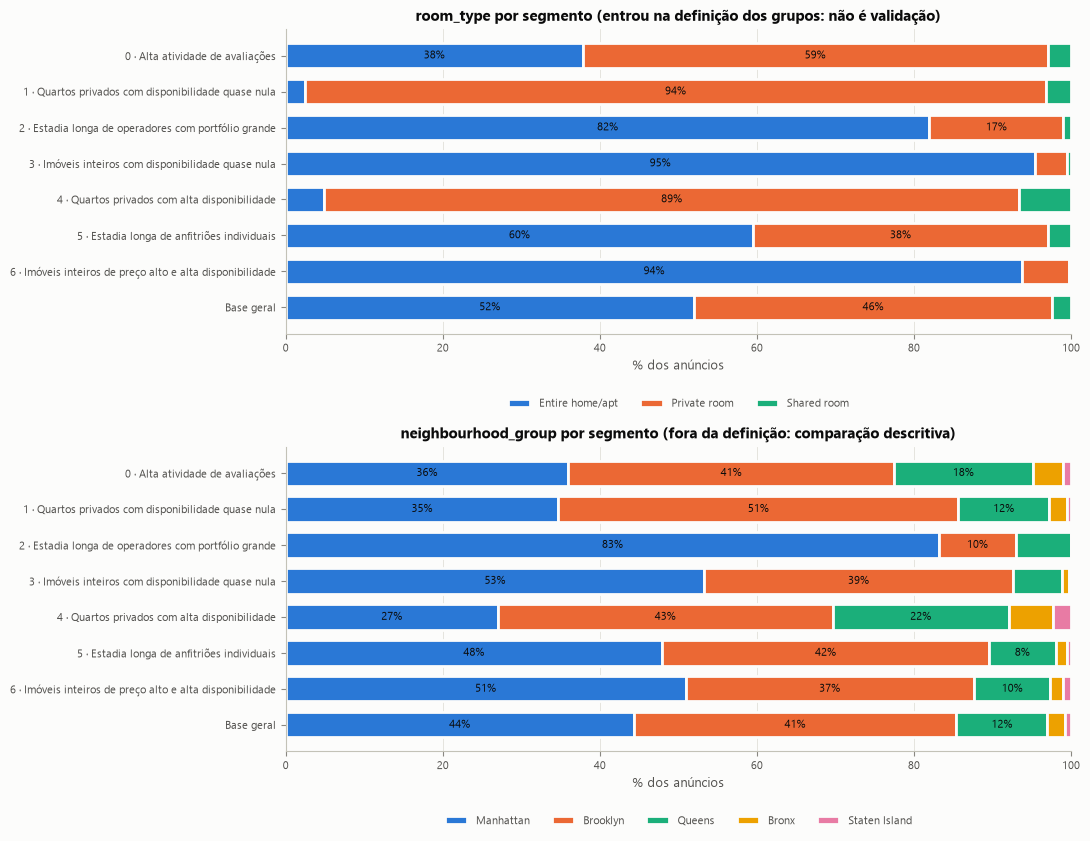

room_type,Entire home/apt,Private room,Shared room
cluster,,,
0,37.800,59.200,3.000
1,2.500,94.300,3.200
2,82.000,17.000,1.000
3,95.400,4.100,0.500
4,4.900,88.500,6.600
5,59.500,37.500,2.900
6,93.800,5.900,0.300
Base geral,52.000,45.700,2.400


neighbourhood_group,Manhattan,Brooklyn,Queens,Bronx,Staten Island
cluster,,,,,
0,36.000,41.500,17.700,3.800,1.100
1,34.700,50.900,11.600,2.300,0.500
2,83.200,9.700,7.000,0.000,0.000
3,53.300,39.300,6.300,0.800,0.300
4,27.000,42.600,22.400,5.600,2.300
5,47.900,41.600,8.500,1.400,0.500
6,50.900,36.700,9.800,1.600,1.000
Base geral,44.300,41.100,11.600,2.200,0.800


In [26]:
room_composition = profiling.composition_table(segments, "cluster", "room_type", config.ROOM_TYPE_ORDER, segment_order)
group_composition = profiling.composition_table(segments, "cluster", "neighbourhood_group",
                                                config.NEIGHBOURHOOD_GROUP_ORDER, segment_order)
room_composition.to_csv(config.REPORTS_DIR / "segment_composition_room_type.csv")
group_composition.to_csv(config.REPORTS_DIR / "segment_composition_neighbourhood_group.csv")
relabel = {**segment_labels, "Base geral": "Base geral"}
fig, axes = plt.subplots(2, 1, figsize=(11, 8.5))
plots.stacked_share_bars(axes[0], room_composition.rename(index=relabel))
axes[0].set_title("room_type por segmento (entrou na definição dos grupos: não é validação)")
plots.stacked_share_bars(axes[1], group_composition.rename(index=relabel))
axes[1].set_title("neighbourhood_group por segmento (fora da definição: comparação descritiva)")
fig.tight_layout()
plots.save_figure(fig, "segment_composition")
plt.show()
display(room_composition.round(1))
group_composition.round(1)

### 8.2 Distribuições por segmento

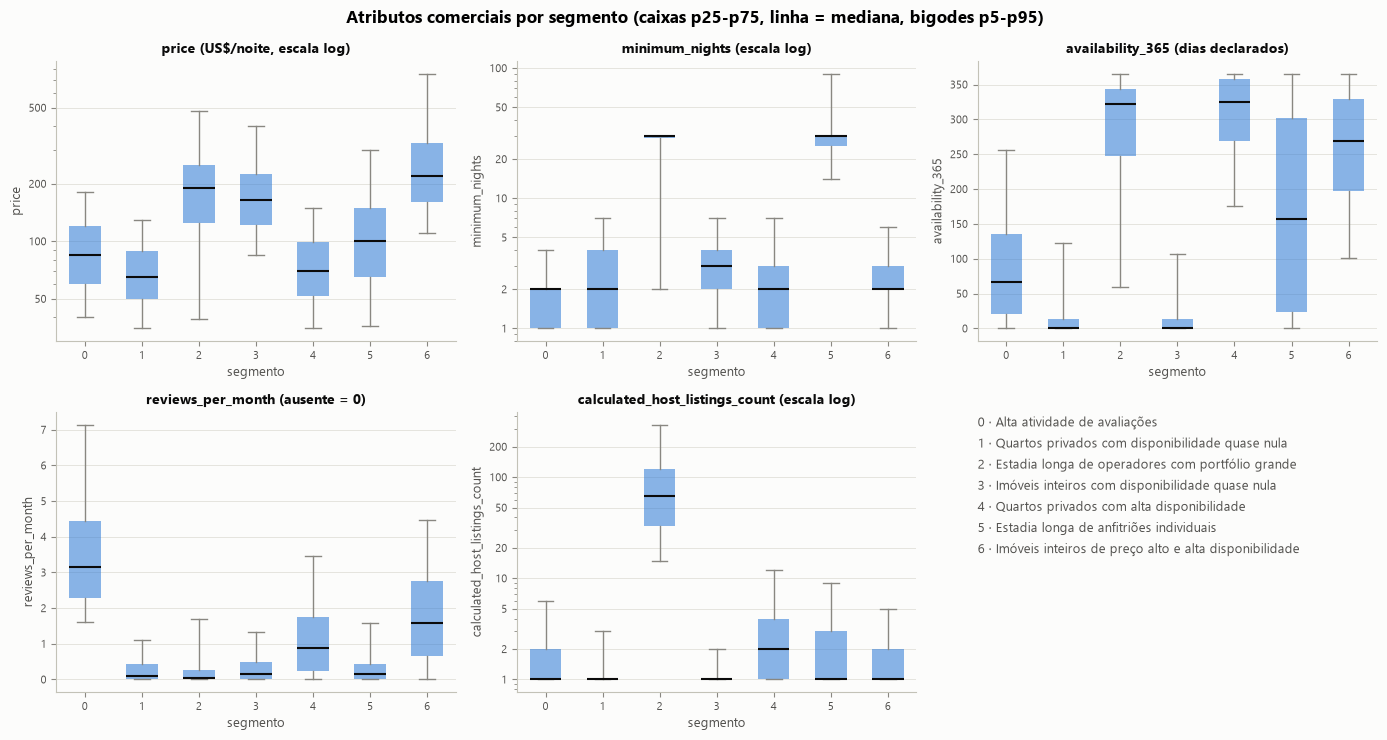

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
box_panels = [
    ("price", True, "price (US$/noite, escala log)"),
    ("minimum_nights", True, "minimum_nights (escala log)"),
    ("availability_365", False, "availability_365 (dias declarados)"),
    ("reviews_per_month", False, "reviews_per_month (ausente = 0)"),
    ("calculated_host_listings_count", True, "calculated_host_listings_count (escala log)"),
]
box_data = segments.assign(reviews_per_month=segments["reviews_per_month"].fillna(0))
for ax, (column, log_scale, title) in zip(axes.flat, box_panels):
    plots.boxplot_by_group(ax, box_data, column, "cluster", segment_order, log_scale=log_scale)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("segmento")
legend_ax = axes.flat[5]
legend_ax.axis("off")
legend_ax.text(0, 1, "\n".join(segment_labels[c] for c in segment_order), va="top", fontsize=9, color=plots.INK_SECONDARY,
               linespacing=1.8)
fig.suptitle("Atributos comerciais por segmento (caixas p25-p75, linha = mediana, bigodes p5-p95)", fontsize=12,
             fontweight="bold")
fig.tight_layout()
plots.save_figure(fig, "segment_distributions")
plt.show()

### 8.3 PCA 2D: visualização, não validação

O PCA projeta o espaço R2-B de 8 dimensões em 2 componentes, só para **visualizar**. A projeção perde informação e pode distorcer
distâncias: grupos sobrepostos em 2D podem estar separados nas dimensões descartadas. Por isso **nenhuma métrica** deste projeto
é calculada no PCA.

variância explicada: PC1 = 30.5%, PC2 = 23.3%, total = 53.7%


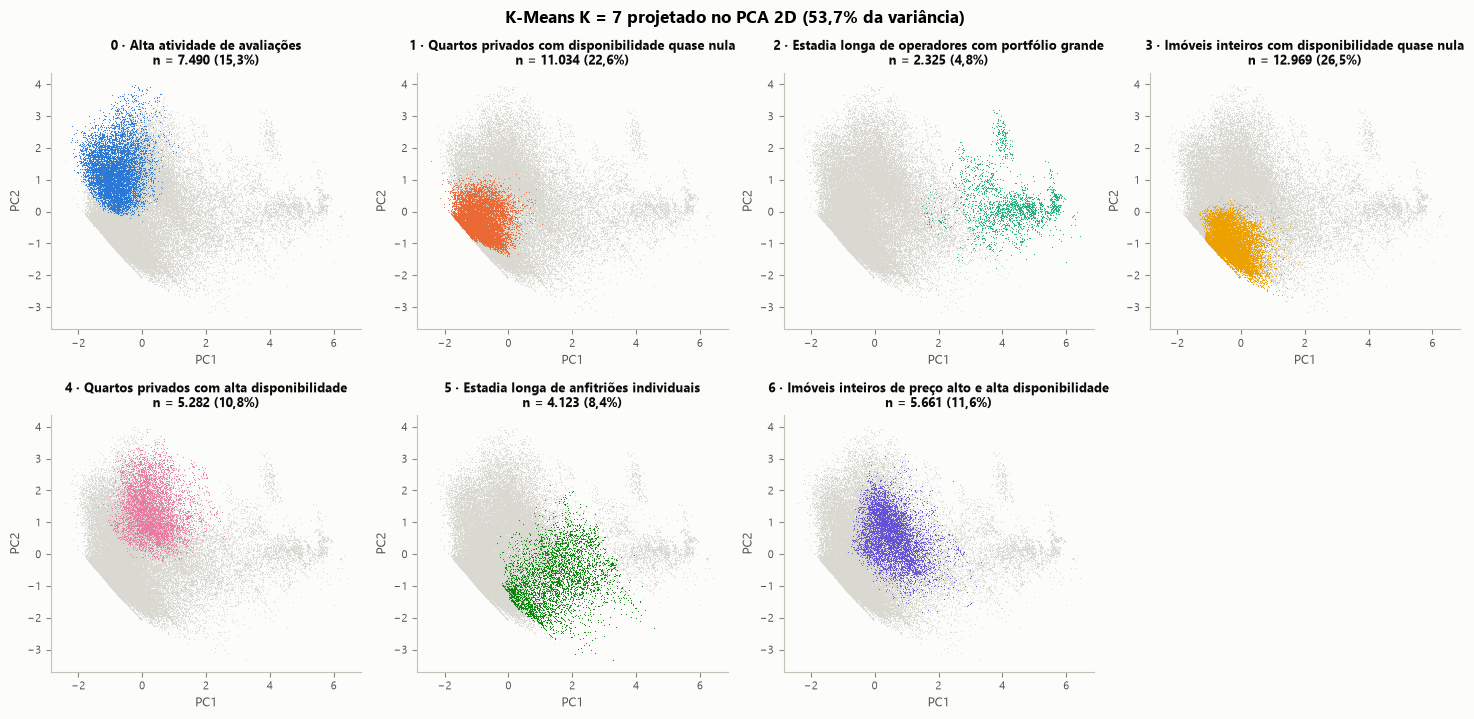

,PC1,PC2
price,0.280,-0.300
minimum_nights,0.540,-0.280
availability_365,0.480,0.510
reviews_per_month,-0.150,0.690
calculated_host_listings_count,0.590,0.220
room_type_Entire home/apt,0.110,-0.160
room_type_Private room,-0.110,0.140
room_type_Shared room,-0.000,0.010


In [28]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=config.RANDOM_STATE).fit(X_b)
coords = pca.transform(X_b)
explained = pca.explained_variance_ratio_
print(f"variância explicada: PC1 = {explained[0]:.1%}, PC2 = {explained[1]:.1%}, total = {explained.sum():.1%}")
loadings = pd.DataFrame(pca.components_.T, index=short_names, columns=["PC1", "PC2"])
pca_frame = segments.assign(PC1=coords[:, 0], PC2=coords[:, 1])
fig = plots.scatter_small_multiples(pca_frame, "PC1", "PC2", "cluster", segment_order, colors=segment_colors,
                                    titles=segment_labels, ncols=4, point_size=0.6, panel_size=(3.7, 3.5))
fig.suptitle(f"K-Means K = 7 projetado no PCA 2D ({explained.sum():.1%} da variância)".replace(".", ","),
             fontsize=12, fontweight="bold", y=1.02)
plots.save_figure(fig, "segment_pca")
plt.show()
loadings.round(2)

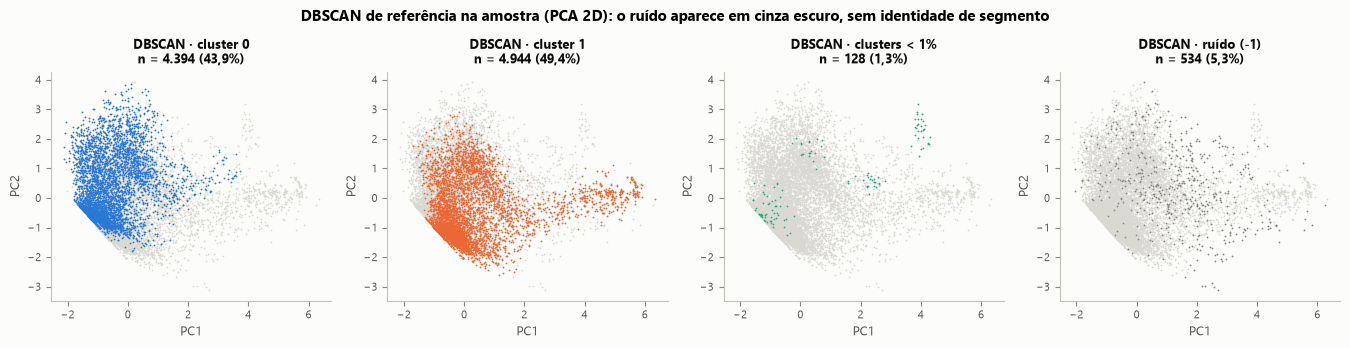

In [29]:
dbscan_pca = reference_frame.assign(PC1=coords[dbscan_idx, 0], PC2=coords[dbscan_idx, 1])
dbscan_groups = [g for g in groups_order]
dbscan_colors = {g: (plots.NOISE_GRAY if g == "ruído (-1)" else plots.SERIES_COLORS[i]) for i, g in enumerate(dbscan_groups)}
dbscan_titles = {g: f"DBSCAN · {g}" for g in dbscan_groups}
fig = plots.scatter_small_multiples(dbscan_pca, "PC1", "PC2", "dbscan_group", dbscan_groups, colors=dbscan_colors,
                                    titles=dbscan_titles, ncols=len(dbscan_groups), point_size=1.5, panel_size=(3.4, 3.3))
fig.suptitle("DBSCAN de referência na amostra (PCA 2D): o ruído aparece em cinza escuro, sem identidade de segmento",
             fontsize=11, fontweight="bold", y=1.04)
plots.save_figure(fig, "dbscan_pca")
plt.show()

**Leitura do PCA.**

- **Variância explicada:** os dois componentes explicam **53,7%** da variância (30,5% + 23,3%), e **46,3% ficam de fora** do gráfico.
- **PC1 (eixo "operação e estadia longa"):** carrega portfólio do anfitrião (0,59), estadia mínima (0,54) e disponibilidade (0,48).
- **PC2 (eixo "atividade"):** carrega avaliações por mês (0,69) e disponibilidade (0,51), com preço (−0,30) e estadia mínima (−0,28)
  em sentido oposto.
- **Posição dos segmentos:**
  - 2 e 5 (estadias longas) ficam à direita no PC1;
  - 0 (alta atividade) fica no alto do PC2;
  - 4 e 6 (alta disponibilidade) ficam numa região intermediária.
- **Sobreposição que é só da projeção:** os segmentos 1 e 3 se sobrepõem quase por completo em 2D. Eles diferem principalmente em
  `room_type` (94% quartos privados contra 95% imóveis inteiros), e as dummies quase não carregam nos dois componentes (|carga| ≤
  0,16). No espaço original estão a √2 de distância nessas dimensões. É o exemplo que o enunciado pede: sobreposição em 2D **não**
  prova mistura no espaço completo, e separação em 2D não seria prova de qualidade.
- **DBSCAN:** na projeção da amostra, o ruído (cinza escuro) se espalha sobretudo para a direita do PC1, na região das estadias
  longas e dos portfólios grandes.

### 8.4 Mapa dos segmentos

Coordenadas originais (`longitude` × `latitude`), com a proporção corrigida para NYC. A localização **não** entrou na
clusterização: o mapa mostra onde os segmentos ficam, sem que isso os defina.

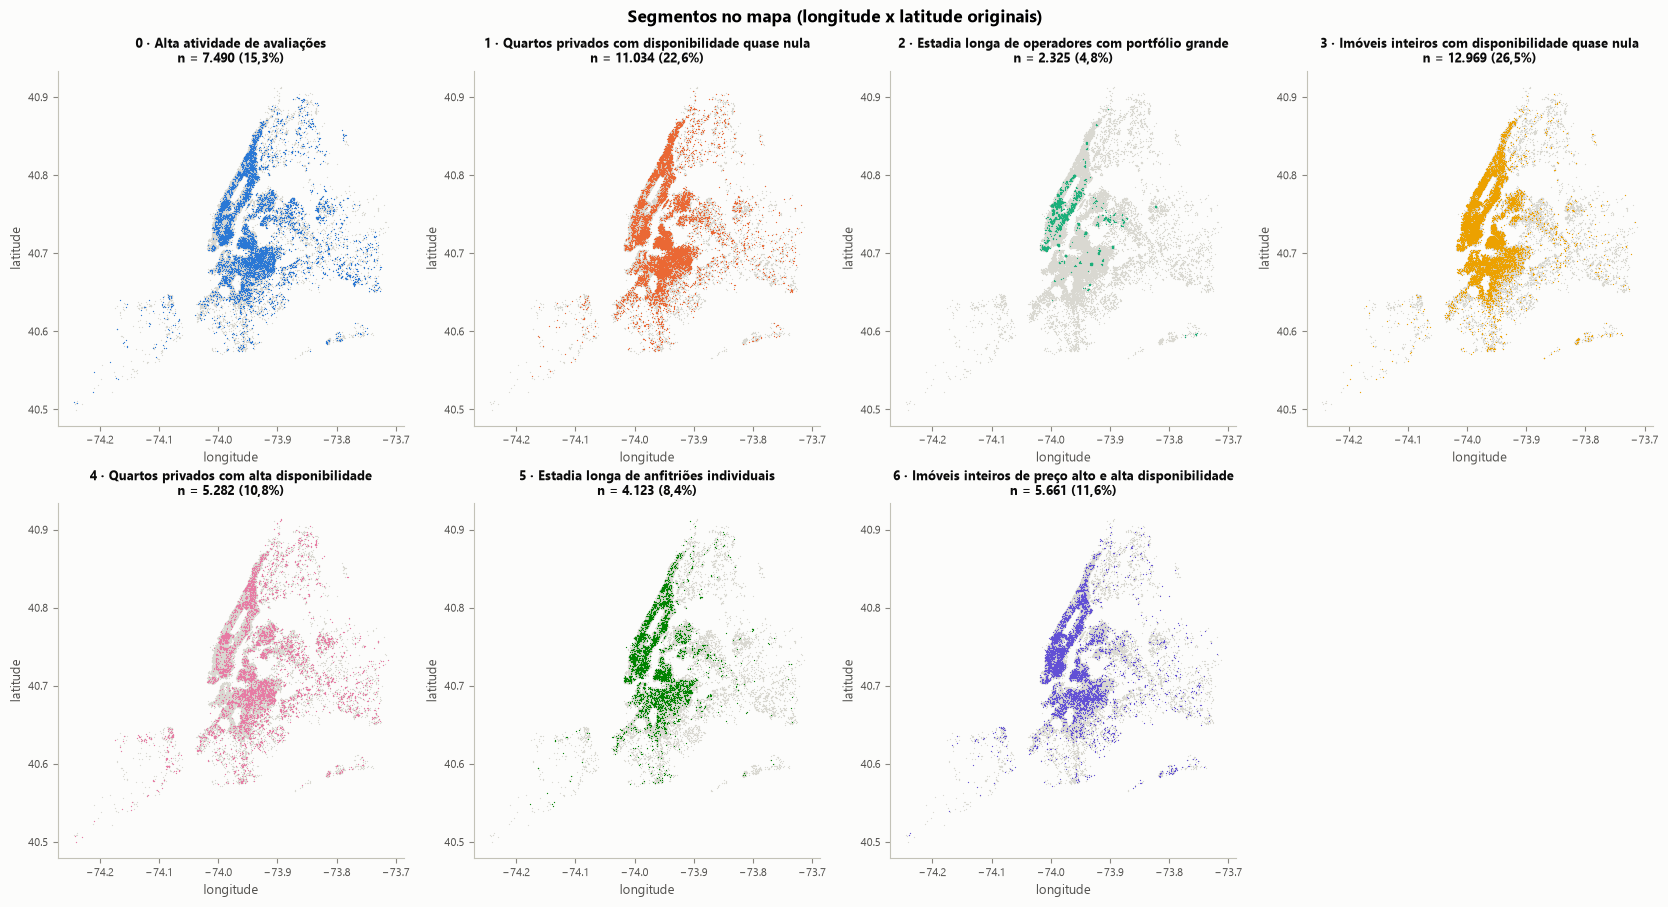

In [30]:
fig = plots.map_small_multiples(segments, "cluster", segment_order, colors=segment_colors, titles=segment_labels,
                                ncols=4, point_size=0.8)
fig.suptitle("Segmentos no mapa (longitude x latitude originais)", fontsize=12, fontweight="bold", y=1.02)
plots.save_figure(fig, "segment_map")
plt.show()

**Leitura dos segmentos** (medianas; tabela completa em `reports/segment_profiles_kmeans.csv`).

| # | Segmento | % | Preço | Estadia mín. | Disponib. | Aval./mês | Anúncios do anfitrião |
|---|---|---|---|---|---|---|---|
| 0 | Alta atividade de avaliações | 15,3 | US$ 85 | 2 | 66 | **3,16** | 1 |
| 1 | Quartos privados com disponibilidade quase nula | 22,6 | US$ 65 | 2 | **0** | 0,10 | 1 |
| 2 | Estadia longa de operadores com portfólio grande | 4,8 | US$ 189 | **30** | 322 | 0,05 | **65** |
| 3 | Imóveis inteiros com disponibilidade quase nula | 26,5 | US$ 165 | 3 | **0** | 0,15 | 1 |
| 4 | Quartos privados com alta disponibilidade | 10,8 | US$ 70 | 2 | **325** | 0,88 | 2 |
| 5 | Estadia longa de anfitriões individuais | 8,4 | US$ 100 | **30** | 157 | 0,14 | 1 |
| 6 | Imóveis inteiros de preço alto e alta disponibilidade | 11,6 | **US$ 220** | 2 | 269 | 1,59 | 1 |

- **Distribuições:** os boxplots mostram separações nítidas em uma ou duas variáveis por segmento:
  - estadia mínima nos segmentos 2 e 5;
  - disponibilidade nos segmentos 1 e 3 (p75 de 13–14 dias) contra 2, 4 e 6 (p25 ≥ 197);
  - avaliações por mês no segmento 0;
  - portfólio no segmento 2.

  Nas demais variáveis, as caixas se sobrepõem. Os segmentos são regiões de um contínuo, não ilhas.
- **Composição por distrito** (fora da definição dos grupos):
  - o segmento 2 tem **83%** dos anúncios em Manhattan, contra 44% na base, e no mapa aparece concentrado ali, com pequenos núcleos
    em Brooklyn e Queens;
  - os segmentos 4 e 0 pesam mais em Queens (22% e 18%, contra 12% na base);
  - os demais acompanham a base.

  Os segmentos **não** são recortes geográficos.
- **Composição por `room_type`:** é parte da definição dos grupos e não deve ser lida como validação.
- **Cuidados de nomenclatura:**
  - "disponibilidade quase nula" descreve a disponibilidade **declarada** (mediana 0; 64%–69% com zero), e não lotação nem inatividade
    comprovada;
  - "alta atividade de avaliações" não significa satisfação nem receita.

### 8.5 Quais segmentos são mais distintos

Distância de cada centróide ao centro da base (média de todos os pontos), no próprio espaço R2-B. É uma medida geométrica de quanto
o perfil médio do segmento se afasta do anúncio médio. A tabela mostra também o desvio de cada variável, em desvios-padrão.

In [31]:
centers = pd.DataFrame(final_model.cluster_centers_, columns=short_names, index=segment_order)
global_center = X_b.mean(axis=0)
distinctness = pd.DataFrame({
    "segment": [name_map[c] for c in segment_order],
    "distância do centróide ao centro da base": np.linalg.norm(final_model.cluster_centers_ - global_center, axis=1),
}, index=segment_order).join(centers.iloc[:, :len(config.FEATURE_NUMERIC)].add_prefix("z_"))
distinctness = distinctness.sort_values("distância do centróide ao centro da base", ascending=False)
distinctness.to_csv(config.REPORTS_DIR / "segment_distinctness.csv")
distinctness.round(2)

,segment,distância do centróide ao centro da base,z_price,z_minimum_nights,z_availability_365,z_reviews_per_month,z_calculated_host_listings_count
2,Estadia longa de operadores com portfólio grande,4.480,0.570,1.910,1.290,-0.600,3.730
5,Estadia longa de anfitriões individuais,2.300,-0.150,2.200,0.380,-0.510,-0.000
6,Imóveis inteiros de preço alto e alta disponib...,1.810,1.110,-0.280,1.100,0.630,-0.200
4,Quartos privados com alta disponibilidade,1.800,-0.660,-0.450,1.450,0.180,0.270
0,Alta atividade de avaliações,1.750,-0.400,-0.540,-0.190,1.590,-0.100
1,Quartos privados com disponibilidade quase nula,1.440,-0.770,-0.300,-0.700,-0.570,-0.290
3,Imóveis inteiros com disponibilidade quase nula,1.300,0.620,-0.160,-0.720,-0.510,-0.390


**Leitura: os três segmentos mais distintos** (distância do centróide ao centro da base, em R2-B).

1. **Segmento 2, estadia longa de operadores com portfólio grande (distância 4,48):**
   - portfólio do anfitrião +3,7 desvios-padrão (mediana de **65 anúncios**, contra 1 na base);
   - estadia mínima +1,9 dp (**30 noites**; 74% com 30 ou mais);
   - disponibilidade +1,3 dp (**322 dias**);
   - avaliações −0,6 dp (**0,05/mês**);
   - preço mediano de US$ 189.
2. **Segmento 5, estadia longa de anfitriões individuais (2,30):**
   - estadia mínima +2,2 dp (**30 noites**; 67% com 30 ou mais), com anfitrião de **1 anúncio**;
   - as demais variáveis ficam perto da média: US$ 100 e disponibilidade mediana de 157 dias.
3. **Segmento 6, imóveis inteiros de preço alto e alta disponibilidade (1,81):**
   - preço +1,1 dp (**US$ 220**; p25–p75 = 160–325);
   - disponibilidade +1,1 dp (**269 dias**);
   - avaliações +0,6 dp (**1,59/mês**);
   - 94% imóveis inteiros.

Logo atrás vêm o segmento 4 (1,80: disponibilidade de 325 dias em quartos privados) e o 0 (1,75: avaliações +1,6 dp, com 3,16 por
mês). Os dois maiores segmentos, 1 e 3, são os mais próximos do anúncio médio (1,44 e 1,30).

## 9. Decisão final

**Métricas × interpretação**

- **Onde os índices convergem:** em K = 7 (melhor Davies-Bouldin, Silhouette no patamar de 0,28 e Calinski-Harabasz 1% abaixo do
  máximo).
- **Onde divergem:**
  - o Silhouette prefere K = 2 (0,392), com 89% da base num grupo só;
  - o Calinski-Harabasz prefere K = 6;
  - os maiores Silhouettes do DBSCAN (0,52–0,56) vêm de soluções com um grupo de 96%–99%.
- Em todos esses casos, o índice mais alto aponta para a solução menos útil.

**A escala alterou a estrutura?** Sim, por completo. Sem `StandardScaler`, a distância é 99,98% disponibilidade, e a partição quase
não se parece com a normalizada (ARI 0,15).

**Grupos comerciais ou recortes geográficos?** Comerciais:

- as features de R2 descrevem preço, condições de estadia, disponibilidade declarada, atividade e portfólio;
- a geografia só aparece como consequência (segmento 2 com 83% em Manhattan);
- incluir o distrito (R3) não cria recortes geográficos (ARI 0,951).

**O DBSCAN trouxe ganho de interpretação?** Não como segmentação:

- ele reproduz `room_type` (ARI 0,993) ou deixa 38% ou mais da amostra como ruído;
- o ganho é **diagnóstico**: o ruído marca os anúncios atípicos, que se concentram nas estadias longas e na alta disponibilidade, e
  a configuração fina revela grupos de anúncios quase idênticos de grandes operadores;
- ele não tem `predict` para anúncios novos.

**Segmentação escolhida: K-Means, K = 7, representação R2 com `StandardScaler`.** Não é a líder absoluta de nenhum índice
isolado. O que pesou foi o equilíbrio entre os critérios:

| Critério | K-Means K = 7 (R2-B) |
|---|---|
| Separação matemática | moderada (Silhouette 0,28): os segmentos são regiões de um contínuo, com fronteiras difusas, não grupos isolados |
| Cobertura | 100% dos anúncios (o DBSCAN de referência cobre 94,7%, com grupos tautológicos) |
| Robustez | ARI 0,996 entre 5 sementes; ARI 0,97 entre o modelo da base e o reajustado na amostra |
| Simplicidade | 7 grupos, o menor com 4,8% (2.325 anúncios); pré-processamento simples e reproduzível |
| Utilidade | perfis distintos e nomeáveis em unidades de negócio; inferência em anúncios novos sem retreinar |

**Limitações**

- A separação moderada exige tratar os nomes como **resumos de tendência**: um anúncio perto da fronteira poderia caber em dois
  segmentos.
- `room_type` faz parte da definição. Comparar com ele não valida a solução, e não existe nenhum rótulo verdadeiro que permita
  validar.
- Os dados são de 2019, e `availability_365` e as avaliações não medem ocupação, receita nem satisfação.

## 10. Respostas às perguntas finais do enunciado

**1. Qual é a diferença entre classificar e clusterizar? Por que não há ROC-AUC, KS ou accuracy aqui?**
Classificar é aprender a reproduzir um rótulo conhecido. Clusterizar é descobrir grupos sem rótulo. ROC-AUC, KS e accuracy comparam
previsões com respostas verdadeiras, que aqui não existem. Medir "acerto" contra `room_type` seria tautológico, porque ele é input
da representação.

**2. Que significado tem a distância Euclidiana neste dataset? O que mudou ao normalizar?**
É a raiz da soma das diferenças quadráticas nas features transformadas: log do preço, log da estadia mínima, disponibilidade, log das
avaliações por mês, log do portfólio e dummies de `room_type`. "Parecido" é "perto nesse espaço".

- Sem normalizar, `availability_365` responde por 99,98% da distância.
- Normalizando, cada numérica pesa 18,1% e `room_type`, 9,4%.
- A partição muda quase por completo (ARI 0,15), e no exemplo dos anúncios hipotéticos a resposta a "quem é parecido" se inverte.

**3. Como funciona o K-Means e por que a inertia tende a cair quando K aumenta?**
O ciclo é inicializar os centros (`k-means++`), atribuir cada ponto ao centro mais próximo, recalcular os centros como médias e
repetir até convergir. O objetivo é minimizar a inertia, a soma das distâncias quadráticas aos centróides. Com mais centros, a
melhor solução nunca fica pior: basta manter os K centros antigos e acrescentar um. Por isso a inertia cai de 214.980 (K = 2) para
82.210 (K = 10) sem que os grupos fiquem necessariamente mais úteis.

**4. Por que as métricas discordam sobre o melhor K? Qual K foi escolhido e por quê?**
Elas medem coisas diferentes:

- o Silhouette compara a coesão de cada ponto com o grupo vizinho mais próximo e premia uma divisão grande e bem separada (K = 2);
- o Davies-Bouldin olha o pior par de grupos;
- o Calinski-Harabasz compara as dispersões entre grupos e dentro deles.

Escolhi **K = 7**: melhor Davies-Bouldin, Silhouette no patamar, Calinski-Harabasz 1% abaixo do máximo, Elbow perdendo força,
estabilidade de 0,996 e menor grupo com 4,8%. Além disso, os perfis são distintos e nomeáveis.

**5. Como o OneHot de `room_type` e `neighbourhood_group` influencia as distâncias?**
Cada dummy vale 0 ou 1. Dois anúncios de tipos diferentes diferem em duas dummies, o que soma 2 à distância quadrática (√2 na
distância), cerca de 18% da distância quadrática média (11,04). Na média, as dummies de `room_type` pesam 9,4% (R2), e as de
`neighbourhood_group` somariam mais 10,1% (R3). Por serem discretas, funcionam como cortes duros: 4 dos 7 segmentos têm 88% ou mais
de um único tipo, e com `eps` < √2 o DBSCAN não consegue juntar tipos diferentes.

**6. Quais as diferenças conceituais entre centróides do K-Means e densidade do DBSCAN?**

- **K-Means:** resume cada grupo por uma média, precisa de K, atribui **todos** os pontos (cobertura de 100%) e favorece grupos
  compactos e convexos.
- **DBSCAN:** define grupos como regiões densas conectadas, de qualquer formato, sem K. Deixa pontos isolados como ruído, depende
  de `eps` e `min_samples` e não tem `predict`.

**7. O que `eps` e `min_samples` controlam? Qual percentual dos anúncios foi classificado como ruído?**
`eps` é o raio da vizinhança, e `min_samples` é o número mínimo de pontos na vizinhança (contando o próprio) para um ponto ser core.

| Configuração | Ruído |
|---|---|
| Referência (`eps = 0,9`, `min_samples = 16`) | **5,3%** da amostra (534 de 10.000) |
| Fina (`eps = 0,5`, `min_samples = 16`) | 38,2% |
| Grade inteira em R2 | de 0,2% (`eps = 1,5`, `min_samples = 8`) a 76,0% (`eps = 0,3`, `min_samples = 32`) |

**8. Quando Silhouette, Davies-Bouldin e Calinski-Harabasz não são aplicáveis? Como você tratou o ruído?**
Não são aplicáveis quando a população avaliada tem menos de 2 grupos ou um grupo por ponto. Isso aconteceu, por exemplo, no DBSCAN
só numérico com `eps = 0,9` e `min_samples = 32`, que deixou um único cluster; o registro foi "não aplicável", sem valor inventado.
O ruído:

- não é segmento;
- fica fora das métricas, com a cobertura reportada (94,7% na referência);
- aparece em cinza nos gráficos;
- na comparação justa, o K-Means também foi avaliado nos mesmos pontos não ruído.

**9. Os resultados no PCA 2D comprovam a qualidade da separação no espaço original?**
Não. Os dois componentes explicam 53,7% da variância, e 46,3% ficam fora do gráfico. Os segmentos 1 e 3 se sobrepõem em 2D, mas no
espaço original estão a √2 de distância nas dimensões de `room_type`, que quase não carregam nos componentes. Todas as métricas
foram calculadas no espaço de 8 dimensões.

**10. Quais três segmentos têm os perfis mais distintos?**
Ver a seção 8.5:

- **segmento 2:** 65 anúncios por anfitrião, 30 noites, 322 dias disponíveis, 0,05 avaliação/mês;
- **segmento 5:** 30 noites com anfitrião de 1 anúncio;
- **segmento 6:** US$ 220, 269 dias disponíveis, 1,59 avaliação/mês.

**11. Comparar um cluster com `room_type` é validação independente, se `room_type` foi usado para construí-lo?**
Não. A composição por `room_type` é parte da definição dos grupos, e o DBSCAN mostra o extremo disso (ARI 0,993 com `room_type`).
`neighbourhood_group`, que ficou fora da representação, permite uma comparação descritiva, como os 83% do segmento 2 em Manhattan.
Mesmo assim, isso também não é validação: não existe rótulo verdadeiro.

**12. Que utilidade comercial a segmentação pode ter? Que limitações impedem concluir ocupação, faturamento ou causalidade?**
Usos possíveis:

- comunicação diferenciada (por exemplo, operadores com portfólio grande e estadia longa, em comparação com anfitriões individuais);
- revisão do inventário nos segmentos 1 e 3, que somam 49% da base e têm disponibilidade declarada quase nula e pouca atividade;
- referências de preço por perfil.

Limitações:

- `availability_365` é disponibilidade **declarada**, não ocupação;
- avaliações não medem reservas, receita nem satisfação;
- não há dados de transação;
- o snapshot é de 2019;
- os segmentos são descritivos: não explicam causas nem garantem que uma ação mude o comportamento de um anúncio.

**13. Por que a solução final é preferível às alternativas, mesmo sem maximizar todas as métricas?**
As líderes de cada índice são degeneradas ou enganosas:

- K = 2: Silhouette de 0,392, com 89% da base num grupo;
- cenário sem scaling: Silhouette de 0,73, só fatiando a disponibilidade;
- DBSCAN: Silhouette de 0,52–0,56 com um grupo de 96% a 99%, ou grupos idênticos a `room_type`.

K = 7 em R2-B equilibra separação, cobertura total, robustez, simplicidade e utilidade (seção 9).

**14. Como o script aplica a segmentação a um novo anúncio sem refazer o treinamento? Por que isso não é igualmente direto com o
DBSCAN?**
`scripts/train.py` salva com `joblib` o `Pipeline` completo: pré-processamento com os limites, o scaler e o encoder aprendidos,
mais o `KMeans` ajustado. O SHA-256 do arquivo fica registrado em `artifacts/metadata.json`. `scripts/segment.py` carrega esse
objeto (conferindo o hash), valida as colunas e chama `predict`, que aplica as mesmas transformações e atribui o anúncio ao
**centróide mais próximo**, sem reajustar nada. Linhas fora do domínio do treino, como preço < 1 ou `room_type` desconhecido,
ficam sem segmento, com o motivo registrado. Aplicado ao próprio `AB_NYC_2019.csv`, o script reproduz os 48.884 rótulos do treino.

O DBSCAN não tem centróides nem `predict`. O rótulo de um ponto depende da densidade entre os pontos do ajuste, e acrescentar pontos
pode criar novos cores, fundir grupos ou transformar ruído em cluster. Atribuir um anúncio novo exigiria uma regra externa ao
algoritmo (por exemplo, "o core mais próximo dentro de `eps`"), e este projeto não simula essa regra.